# ANCP D3 — Exploratory Data Analysis: Westside Stylist Mirror

**Group M · Module M3 (Exploratory analysis) · Lead: C Prashanth · Linked outcomes: CO2, CO4**

This notebook explores the H&M purchase data (10% customer sample) that serves as our proxy for Westside's purchase history. It follows the D1 charter and the D2 data audit. The order is deliberate: business questions and hypotheses are written **before** any data is loaded, then data is loaded, cleaned and checked for bias, and only then explored.

**How to read it.** Every section ends with a short "so what". The insight log (section 9) collects the findings and the summary page (section 10) says how they shape modelling in M4. A two-page PDF summary is delivered separately.

**Reproducibility.** *Restart & Run All* works. The data folder is found automatically (set the `HM_DATA_DIR` environment variable to override). A small reference file, `reference/full_population_profile.json`, was built once from the full 31.8M-row transaction file by `build_full_population_profile.py`; the notebook uses it to test whether the 10% sample is representative.

## 0. Setup

In [1]:
import os, json, warnings, math, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats, sparse

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
rng = np.random.default_rng(SEED)
T0 = time.time()

HERE = Path.cwd()
FIG, OUT, REF = HERE / "figures", HERE / "outputs", HERE / "reference"
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

def find_data_dir():
    for c in [os.environ.get("HM_DATA_DIR"), r"C:\Users\cpras\Downloads\H&M", str(HERE / "data"), str(HERE.parent / "data")]:
        if c and (Path(c) / "transactions_train_sample10pct.csv").exists():
            return Path(c)
    raise FileNotFoundError("Put the H&M csv files in ./data or set HM_DATA_DIR")
DATA = find_data_dir()

# Colour system: validated categorical order (blue, orange, aqua, yellow, magenta, green, violet, red);
# one-hue blue ramp for magnitude; blue/orange pair with a neutral midpoint for ratios around 1.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948", ink="#0b0b0b", ink2="#52514e",
         muted="#898781", grid="#e1e0d9", mid="#f0efec")
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#e9f2fd", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("blue_orange", ["#256abf", "#9ec5f4", C["mid"], "#f3b79b", "#c8501f"])
DEPT_COL = {"Ladieswear": C["blue"], "Divided": C["orange"], "Menswear": C["aqua"], "Sport": C["violet"]}

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 10.5, "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"],
    "ytick.color": C["ink2"], "text.color": C["ink"], "axes.edgecolor": C["muted"], "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.prop_cycle": mpl.cycler(color=[C[k] for k in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
KEY = {}   # headline numbers, written to outputs/key_numbers.json for the PDF summary

def save(fig, name):
    fig.text(0.005, -0.035, f"Figure {int(name[3:5])}", fontsize=9, color=C["muted"], ha="left")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
print("data folder:", DATA)

data folder: C:\Users\cpras\Downloads\H&M


## 1. Business context, questions and hypotheses (stated before any analysis)

**Decision this EDA supports.** Whether, and how, a Westside "stylist mirror" that reads a member's purchase history and suggests complete outfits is worth building, and what the M4 models (best-seller baseline, recommender, outfit matcher, demand forecast) must handle. The charter's success metrics (MAP@12 against a best-seller baseline, items per bill, fairness across groups, forecast WAPE) are the yardsticks.

**Business questions (BQ)**

| ID | Business question | Why it matters for the decision |
|---|---|---|
| BQ1 | Is there headroom for outfit suggestions: do shoppers buy thin baskets? | Sets the size of the "items per bill" prize. |
| BQ2 | Does a shopper's purchase history carry signal beyond what everyone else is buying? | Decides whether personalisation can beat the best-seller baseline. |
| BQ3 | Can complementary items (top + bottom) be learned from what is bought together? | Decides whether the outfit matcher can start from transaction data. |
| BQ4 | Is demand stable enough to forecast and to make stock-aware suggestions? | Decides how fresh models must be and whether a static best-seller list works. |
| BQ5 | Do customer segments differ, and who are the target-group shoppers? | Sets fairness checks and who the mirror serves best or worst. |

**Hypotheses.** Each has a direction, a decision rule fixed *now* (thresholds are not changed after seeing results), and the business question it informs. "Visit" means one customer on one day. "Unit" is one item bought. The in-scope data is defined in section 3: adult customers, adult departments, apparel and accessories.

| ID | Hypothesis | Linked BQ | Decision rule (supported if…) | Charter metric it informs |
|---|---|---|---|---|
| H1 | Most visits are thin: shoppers rarely buy a top and a bottom together, so completing the outfit is open headroom. | BQ1 | ≥ 50% of visits contain a single unit **and** ≤ 15% of visits contain both a top and a bottom | Items per bill uplift |
| H2 | A shopper's past purchases predict what they buy next far better than chance: they re-buy the same product types and colours. | BQ2 | History hit rate for product type **and** colour is ≥ 1.5× a same-week random baseline | MAP@12 vs best-seller |
| H3 | Complementary pairs exist in the baskets: top–bottom product-type pairs co-occur more than expected after controlling for basket size and week. | BQ3 | Median adjusted lift of top×bottom type pairs ≥ 1.2 | Outfit-matching accuracy |
| H4 | Demand is long-tailed and churns quickly, so a static best-seller list goes stale. | BQ4 | Top 1% of articles hold < 25% of units **and** the week-to-week overlap (Jaccard) of the top-100 articles is < 0.50 | Best-seller baseline, WAPE |
| H5 | Segments differ: the department mix and basket behaviour change with age, so one policy will serve groups unequally. | BQ5 | Cramér's V of age band × department ≥ 0.15 **and** the single-unit share differs by ≥ 5 points between age bands (bands with ≥ 1,000 customers) | Fairness across groups |
| H6 | Purchases are concentrated in a minority of heavy buyers, who therefore dominate any training data. | BQ2, BQ5 | Top 10% of customers account for ≥ 40% of units | Validity (split by person), weighting |
| H7 | Colour choice is concentrated in a few neutrals and shifts with the season. | BQ3, BQ4 | Top 3 master colours ≥ 50% of units **and** the light/bright share differs by ≥ 5 points between summer and winter months | Colour advice, forecast seasonality |

**Open item, not testable here.** The charter's target group ("low-effort, low-confidence dressers") cannot be observed in transaction data. Section 8 builds a behavioural proxy and flags it as a proxy; the shopper survey planned for M3 must confirm it.

In [2]:
# Decision thresholds fixed BEFORE the data is loaded (single source of truth for the verdict table in section 8).
THR = dict(
    H1_single_min=0.50, H1_pair_max=0.15,
    H2_ratio_min=1.5,
    H3_lift_min=1.2,
    H4_top1pct_max=0.25, H4_jaccard_max=0.50,
    H5_cramer_min=0.15, H5_gap_min=0.05, H5_min_customers=1000,
    H6_top10_min=0.40,
    H7_top3_min=0.50, H7_season_min=0.05,
)
pd.Series(THR, name="threshold").to_frame()

,threshold
H1_single_min,0.500
H1_pair_max,0.150
H2_ratio_min,1.500
H3_lift_min,1.200
H4_top1pct_max,0.250
H4_jaccard_max,0.500
H5_cramer_min,0.150
H5_gap_min,0.050
H5_min_customers,"1,000.000"
H6_top10_min,0.400


## 2. Load the data

Three raw files are used: the 10% customer sample of transactions (all purchases of a random 10% of customers), the article catalogue, and the full customer table. Nothing is modified on disk.

In [3]:
t = time.time()
art = pd.read_csv(DATA / "articles.csv", dtype={"article_id": str}, usecols=[
    "article_id", "product_type_name", "product_group_name", "perceived_colour_master_name",
    "perceived_colour_value_name", "index_group_name", "garment_group_name"])
cust_all = pd.read_csv(DATA / "customers.csv", usecols=[
    "customer_id", "FN", "Active", "club_member_status", "fashion_news_frequency", "age"])
tx = pd.read_csv(DATA / "transactions_train_sample10pct.csv", parse_dates=["t_dat"],
                 dtype={"article_id": str, "sales_channel_id": "int8", "price": "float32"})
tx["cust"], cust_ids = pd.factorize(tx["customer_id"])
tx = tx.drop(columns="customer_id")
cust_s = pd.DataFrame({"customer_id": cust_ids}).merge(cust_all, on="customer_id", how="left")   # index == tx.cust code
print(f"articles {art.shape} | customers (all) {cust_all.shape} | sampled buyers {cust_s.shape} | transactions {tx.shape}")
print(f"date range {tx.t_dat.min().date()} to {tx.t_dat.max().date()} | loaded in {time.time()-t:.0f}s")
assert tx.article_id.isin(art.article_id).all(), "transactions with unknown article"
assert cust_s.age.notna().sum() > 0
tx.head()

articles (105542, 7) | customers (all) (1371980, 6) | sampled buyers (136670, 6) | transactions (3205663, 5)
date range 2018-09-20 to 2020-09-22 | loaded in 10s


,t_dat,article_id,price,sales_channel_id,cust
0,2018-09-20,0505221004,0.015,2,0
1,2018-09-20,0685687003,0.017,2,0
2,2018-09-20,0685687004,0.017,2,0
3,2018-09-20,0685687001,0.017,2,0
4,2018-09-20,0505221001,0.020,2,0


### 2.1 Raw-data quality scan (before any cleaning)

D2 audited the same files; the checks that matter for EDA are repeated here so this notebook stands alone.

In [4]:
key_cols = ["t_dat", "cust", "article_id", "price", "sales_channel_id"]
n_raw = len(tx)
n_dup_extra = int(tx.duplicated(key_cols).sum())
raw_scan = pd.DataFrame({
    "check": ["transaction rows", "exact duplicate rows (beyond the first copy)", "missing values in transactions",
              "price min / max (normalised scale)", "customers missing age", "customers with age > 90",
              "customers with age < 18", "customers missing FN flag", "customers missing club status",
              "first / last transaction date"],
    "result": [f"{n_raw:,}", f"{n_dup_extra:,} ({n_dup_extra/n_raw:.1%})", int(tx.isna().sum().sum()),
               f"{tx.price.min():.5f} / {tx.price.max():.3f}",
               f"{cust_s.age.isna().sum():,} ({cust_s.age.isna().mean():.1%})", int((cust_s.age > 90).sum()),
               int((cust_s.age < 18).sum()), f"{cust_s.FN.isna().mean():.1%}",
               f"{cust_s.club_member_status.isna().mean():.1%}", f"{tx.t_dat.min().date()} / {tx.t_dat.max().date()}"],
})
raw_scan

,check,result
0,transaction rows,"3,205,663"
1,exact duplicate rows (beyond the first copy),"296,434 (9.2%)"
2,missing values in transactions,0
3,price min / max (normalised scale),0.00003 / 0.507
4,customers missing age,"1,598 (1.2%)"
5,customers with age > 90,5
6,customers with age < 18,913
7,customers missing FN flag,65.2%
8,customers missing club status,0.4%
9,first / last transaction date,2018-09-20 / 2020-09-22


**Cleaning decisions** (each is a judgement; the reason is the test of whether it is right)

| # | Issue found | Decision | Reason |
|---|---|---|---|
| 1 | Exact duplicate rows (same customer, day, article, price, channel) | **Keep, as quantity.** Collapse to one line with `qty` | The file has no quantity column. Identical rows are two units bought together, not a logging error, so dropping them would understate basket size. Units are preserved. |
| 2 | Baby/Children department | **Exclude** from the main frame | The buyer is dressing someone else. Outfit advice for the shopper cannot learn from these purchases. |
| 3 | Non-apparel product groups (cosmetics, furniture, stationery, "Unknown", etc.) | **Exclude** | Not part of an outfit. Under 0.1% of units; checked below. |
| 4 | Customers under 18 | **Exclude** | The charter rules out under-18s for the mirror. |
| 5 | Age > 90 (implausible) | Set age to missing | Likely default values. Customer is kept. |
| 6 | Missing age, FN, Active, club status, news frequency | Age: explicit "unknown" band. FN/Active: missing means 0 (not subscribed). Others: "UNKNOWN" | Imputing age would invent a signal; we test whether missingness itself is informative (section 3.3). |
| 7 | Price is on a normalised scale, not a currency | Use as **relative** price only | Absolute rupee or euro claims would be unfounded. |
| 8 | First and last weeks are partial | Drop partial weeks from **weekly** analyses only | Avoids false dips at the window edges. |
| 9 | `sales_channel_id` is an anonymous code (1 or 2) | Keep as code; do not label "store" or "online" | The data dictionary does not say which is which. The mirror is an in-store device, so this matters (see 3.3). |

## 3. Cleaning, and representativeness checks on raw and cleaned data

### 3.1 Build the cleaned frame

In [5]:
ROLE = {"Garment Upper body": "Top", "Garment Lower body": "Bottom", "Garment Full body": "Full-body",
        "Accessories": "Accessory", "Bags": "Accessory", "Shoes": "Footwear", "Socks & Tights": "Hosiery",
        "Underwear": "Underwear", "Nightwear": "Nightwear", "Underwear/nightwear": "Nightwear", "Swimwear": "Swimwear"}
ADULT_DEPTS = ["Ladieswear", "Divided", "Menswear", "Sport"]
AGE_BINS = [0, 17, 24, 34, 44, 54, 64, 200]
AGE_LAB = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
BAND_ORDER = AGE_LAB + ["unknown"]

art["role"] = art.product_group_name.map(ROLE)
art_idx = art.set_index("article_id")

def add_age_band(c, age_col):
    return pd.cut(c[age_col], AGE_BINS, labels=AGE_LAB).astype(object).fillna("unknown")

def clean_customers(c):
    c = c.copy()
    c["age_clean"] = c.age.where(c.age <= 90)                  # decision 5
    c["age_band"] = add_age_band(c, "age_clean")
    c["FN"] = c.FN.fillna(0); c["Active"] = c.Active.fillna(0)  # decision 6
    c["club"] = c.club_member_status.fillna("UNKNOWN")
    c["news"] = c.fashion_news_frequency.replace({"None": "NONE"}).fillna("UNKNOWN")
    c["minor"] = c.age < 18                                      # decision 4
    return c

cust_all_c = clean_customers(cust_all)
cust_s_c = clean_customers(cust_s)

# Decision 1: collapse exact duplicates to quantity
lines = tx.groupby(key_cols, sort=False).size().reset_index(name="qty")
lines = lines.merge(art, on="article_id", how="left")

funnel = [("Raw rows (units)", int(n_raw))]
funnel.append(("After collapsing duplicates: lines", len(lines)))
units = lines.qty.sum();                       funnel.append(("Units, all departments", int(units)))
lines = lines[lines.index_group_name.isin(ADULT_DEPTS)];  funnel.append(("Drop Baby/Children (decision 2)", int(lines.qty.sum())))
lines = lines[lines.role.notna()];             funnel.append(("Drop non-apparel groups (decision 3)", int(lines.qty.sum())))
minor_codes = set(cust_s_c.index[cust_s_c.minor])
lines = lines[~lines.cust.isin(minor_codes)];  funnel.append(("Drop under-18 customers (decision 4)", int(lines.qty.sum())))
lines = lines.reset_index(drop=True)
for c_ in ["index_group_name", "product_type_name", "perceived_colour_master_name", "perceived_colour_value_name", "role"]:
    lines[c_] = lines[c_].astype("category")

# visit = one customer on one day; week starts Monday
lines["vid"] = lines.groupby(["cust", "t_dat"], sort=False).ngroup()
lines["week"] = lines.t_dat - pd.to_timedelta(lines.t_dat.dt.dayofweek, unit="D")
first_week = (tx.t_dat.min() + pd.Timedelta(days=6)).normalize()
first_week = first_week - pd.Timedelta(days=first_week.dayofweek)             # first Monday on/after start
last_week = (tx.t_dat.max() - pd.Timedelta(days=6) - pd.Timedelta(days=(tx.t_dat.max() - pd.Timedelta(days=6)).dayofweek))
lines["wk_ok"] = (lines.week >= first_week) & (lines.week <= last_week)
lines["spend"] = lines.price * lines.qty
for r_ in ["Top", "Bottom", "Full-body", "Accessory"]:
    lines["is_" + r_.lower().replace("-body", "")] = (lines.role == r_)

fun = pd.DataFrame(funnel, columns=["step", "units"])
fun["share of raw"] = fun.units / n_raw
display(fun)
print(f"complete weeks used for weekly analyses: {first_week.date()} to {last_week.date()} (week start dates)")
KEY.update(raw_rows=int(n_raw), dup_rows=n_dup_extra, units_in_scope=int(lines.qty.sum()),
           units_dropped_baby=int(funnel[2][1]-funnel[3][1]), n_customers_sample=int(len(cust_s)),
           n_customers_in_scope=int(lines.cust.nunique()))

,step,units,share of raw
0,Raw rows (units),3205663,1.000
1,After collapsing duplicates: lines,2909229,0.908
2,"Units, all departments",3205663,1.000
3,Drop Baby/Children (decision 2),3082273,0.962
4,Drop non-apparel groups (decision 3),3071946,0.958
5,Drop under-18 customers (decision 4),3066344,0.957


complete weeks used for weekly analyses: 2018-09-24 to 2020-09-14 (week start dates)


In [6]:
# Customer-level and visit-level tables
visits = lines.groupby("vid", sort=True).agg(
    cust=("cust", "first"), date=("t_dat", "first"), week=("week", "first"), units=("qty", "sum"),
    n_lines=("qty", "size"), spend=("spend", "sum"), has_top=("is_top", "max"), has_bottom=("is_bottom", "max"),
    has_full=("is_full", "max"), has_acc=("is_accessory", "max"), channel=("sales_channel_id", "first"),
    dept=("index_group_name", "first"), wk_ok=("wk_ok", "first"))
n_types = lines[["vid", "product_type_name"]].drop_duplicates().groupby("vid").size()
visits["n_types"] = n_types.reindex(visits.index).values
visits["single"] = visits.units == 1
visits["pair"] = visits.has_top & visits.has_bottom
visits = visits.join(cust_s_c[["age_band", "club", "news", "FN", "age_clean"]], on="cust")

cust = visits.groupby("cust").agg(n_visits=("units", "size"), units=("units", "sum"), single_share=("single", "mean"),
                                  spend=("spend", "sum"), first=("date", "min"), last=("date", "max"))
cust["n_types"] = lines[["cust", "product_type_name"]].drop_duplicates().groupby("cust").size().reindex(cust.index).values
cust = cust.join(cust_s_c[["age_band", "club", "news", "FN", "age_clean"]])
print(f"visits {len(visits):,} | customers {len(cust):,} | units {int(visits.units.sum()):,} | mean units/visit {visits.units.mean():.2f}")

visits 887,485 | customers 132,435 | units 3,066,344 | mean units/visit 3.46


### 3.2 Representativeness: is the 10% sample like the full population?

Two comparisons, each done on **raw** and on **cleaned** data:

* **Customers.** The 136k sampled buyers against all 1.37M customers in `customers.csv`, on age, club status and newsletter flags. The standardised mean difference (SMD) is used because with these sample sizes p-values flag everything; |SMD| < 0.1 is the usual "balanced" convention.
* **Transactions.** The sample against the full 31.8M-row file (`reference/full_population_profile.json`), on department mix, channel mix, monthly volume profile, purchases per customer and basket size.

Cleaning changes who and what is in scope, so the cleaned comparison is also a check on the **bias introduced by our own filters**.

In [7]:
def smd(p1, p2, binary=True, sd1=None, sd2=None):
    if binary:
        return (p1 - p2) / math.sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2 + 1e-12)
    return (p1 - p2) / math.sqrt((sd1 ** 2 + sd2 ** 2) / 2)

def cust_metrics(c, age_col, bands_col):
    known = c[age_col].notna()
    out = {"mean age (known)": (c[age_col].mean(), c[age_col].std())}
    for b in ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]:
        out[f"age band {b} (share of known age)"] = ((c.loc[known, bands_col] == b).mean(), None)
    out["age unknown"] = ((~known).mean(), None)
    out["club status ACTIVE"] = ((c.club_member_status == "ACTIVE").mean(), None)
    out["newsletter: Regularly"] = ((c.fashion_news_frequency == "Regularly").mean(), None)
    out["FN flag = 1"] = ((c.FN == 1).mean(), None)
    return out

def cust_rep_table(pop, samp, age_col, band_col, label):
    mp, ms = cust_metrics(pop, age_col, band_col), cust_metrics(samp, age_col, band_col)
    rows = []
    for k in mp:
        (a, sa), (b, sb) = mp[k], ms[k]
        s = smd(b, a, binary=sa is None, sd1=sb, sd2=sa)
        rows.append((k, a, b, s, "OK" if abs(s) < 0.1 else "CHECK"))
    return pd.DataFrame(rows, columns=["metric", f"population ({label})", f"sample ({label})", "SMD", "verdict"]).set_index("metric")

# RAW: untouched attributes
cust_all["age_band_raw"] = add_age_band(cust_all, "age"); cust_s["age_band_raw"] = add_age_band(cust_s, "age")
rep_c_raw = cust_rep_table(cust_all, cust_s, "age", "age_band_raw", "raw")

# CLEANED: cleaned attributes, adults only, and sample restricted to buyers still in scope
pop_c = cust_all_c[~cust_all_c.minor]
smp_c = cust_s_c.loc[cust_s_c.index.isin(lines.cust.unique()) & ~cust_s_c.minor]
rep_c_clean = cust_rep_table(pop_c, smp_c, "age_clean", "age_band", "clean")
rep_c = rep_c_raw.join(rep_c_clean, how="outer", lsuffix=" ", rsuffix="  ")
display(rep_c)
KEY["max_abs_smd_cust_raw"] = float(rep_c_raw.SMD.abs().max()); KEY["max_abs_smd_cust_clean"] = float(rep_c_clean.SMD.abs().max())

,population (raw),sample (raw),SMD,verdict,population (clean),sample (clean),SMD,verdict
metric,,,,,,,,
FN flag = 1,0.348,0.348,0.002,OK,0.348,0.350,0.005,OK
age band 18-24 (share of known age),0.256,0.255,-0.003,OK,0.258,0.262,0.009,OK
age band 25-34 (share of known age),0.290,0.291,0.003,OK,0.292,0.296,0.008,OK
age band 35-44 (share of known age),0.125,0.125,0.002,OK,0.126,0.119,-0.021,OK
age band 45-54 (share of known age),0.187,0.188,0.001,OK,0.189,0.188,-0.001,OK
age band 55-64 (share of known age),0.103,0.102,-0.001,OK,0.103,0.104,0.002,OK
age band 65+ (share of known age),0.032,0.032,-0.003,OK,0.032,0.032,-0.004,OK
age unknown,0.012,0.012,0.001,OK,0.012,0.011,-0.004,OK
club status ACTIVE,0.927,0.927,-0.000,OK,0.927,0.930,0.013,OK


In [8]:
full = json.loads((REF / "full_population_profile.json").read_text())
fm = pd.DataFrame(full["month_index_group"], columns=["month", "dept", "n"])

# --- department mix and monthly profile
def share(s): return s / s.sum()
# raw: all departments, units = raw rows
raw_dept = share(tx.article_id.map(art_idx.index_group_name).value_counts())
full_dept = share(fm.groupby("dept").n.sum())
# clean: adult departments, apparel only vs full population with Baby/Children removed (apparel filter not available in the reference)
clean_dept = share(lines.groupby("index_group_name").qty.sum())
full_dept_adult = share(fm[fm.dept.isin(ADULT_DEPTS)].groupby("dept").n.sum())
dept_tab = pd.DataFrame({"full (raw)": full_dept, "sample (raw)": raw_dept, "full (adult depts)": full_dept_adult, "sample (clean)": clean_dept}).fillna(0)
dept_tab["gap raw (pp)"] = (dept_tab["sample (raw)"] - dept_tab["full (raw)"]) * 100
dept_tab["gap clean (pp)"] = (dept_tab["sample (clean)"] - dept_tab["full (adult depts)"]) * 100

# --- channel mix (raw only: the reference has no channel-by-department split)
ch_full = share(pd.Series(full["sales_channel"]).rename(int).sort_index())
ch_full.index = ch_full.index.astype(int)
ch_samp = share(tx.sales_channel_id.value_counts()).sort_index()
ch_tab = pd.DataFrame({"full (raw)": ch_full, "sample (raw)": ch_samp}); ch_tab["gap (pp)"] = (ch_tab["sample (raw)"] - ch_tab["full (raw)"]) * 100

# --- monthly volume profile
m_full_raw = share(fm.groupby("month").n.sum())
m_samp_raw = share(tx.t_dat.dt.strftime("%Y-%m").value_counts().sort_index())
m_full_ad = share(fm[fm.dept.isin(ADULT_DEPTS)].groupby("month").n.sum())
m_samp_cl = share(lines.assign(m=lines.t_dat.dt.strftime("%Y-%m")).groupby("m").qty.sum())
mon = pd.DataFrame({"full raw": m_full_raw, "sample raw": m_samp_raw, "full adult": m_full_ad, "sample clean": m_samp_cl})
mon_stats = pd.DataFrame({
    "max monthly share gap (pp)": [(mon["sample raw"] - mon["full raw"]).abs().max() * 100, (mon["sample clean"] - mon["full adult"]).abs().max() * 100],
    "correlation of monthly profiles": [mon[["sample raw", "full raw"]].corr().iloc[0, 1], mon[["sample clean", "full adult"]].corr().iloc[0, 1]]},
    index=["raw", "clean"])

display(dept_tab.round(4)); display(ch_tab.round(4)); display(mon_stats)

,full (raw),sample (raw),full (adult depts),sample (clean),gap raw (pp),gap clean (pp)
Baby/Children,0.038,0.038,0.000,0.000,0.020,0.000
Divided,0.225,0.224,0.234,0.233,-0.052,-0.015
Ladieswear,0.642,0.642,0.668,0.668,-0.006,0.005
Menswear,0.056,0.056,0.058,0.058,0.051,0.046
Sport,0.039,0.039,0.041,0.040,-0.013,-0.036


,full (raw),sample (raw),gap (pp)
1,0.296,0.296,-0.019
2,0.704,0.704,0.019


,max monthly share gap (pp),correlation of monthly profiles
raw,0.060,1.000
clean,0.050,1.000


In [9]:
# --- purchases per customer and basket size (raw rows; clean uses units on the in-scope frame)
raw_rows_pc = tx.groupby("cust").size()
q = [.1, .25, .5, .75, .9, .99]
rpc = pd.DataFrame({"full (raw)": [full["rows_per_customer_quantiles"][str(x)] for x in q],
                    "sample (raw)": raw_rows_pc.quantile(q).values,
                    "sample (clean, units)": cust.units.quantile(q).values}, index=[f"p{int(x*100)}" for x in q])
rpc.loc["mean"] = [full["rows_per_customer_mean"], raw_rows_pc.mean(), cust.units.mean()]
rpc["gap raw (%)"] = (rpc["sample (raw)"] / rpc["full (raw)"] - 1) * 100

bs_full = pd.Series(full["basket_size_hist"]).astype(float); bs_full.index = bs_full.index.astype(int)
bs_full_share = bs_full / bs_full.sum()
raw_vis = tx.groupby(["cust", "t_dat"]).size()
bs_raw = raw_vis.value_counts().sort_index(); bs_raw_share = bs_raw / bs_raw.sum()
def cap(s, k=5):
    o = s.copy(); o.index = np.minimum(o.index, k); return o.groupby(level=0).sum()
bs_tab = pd.DataFrame({"full (raw)": cap(bs_full_share), "sample (raw)": cap(bs_raw_share),
                       "sample (clean, units)": cap(visits.units.value_counts(normalize=True).sort_index())})
bs_tab.index = [str(i) if i < 5 else "5+" for i in bs_tab.index]; bs_tab.index.name = "items per visit"
bs_tab.loc["mean items/visit"] = [(bs_full * bs_full.index).sum() / bs_full.sum(), raw_vis.mean(), visits.units.mean()]
display(rpc.round(2)); display(bs_tab.round(4))
KEY["single_raw_full"] = float(bs_full_share.loc[1]); KEY["single_raw_sample"] = float(bs_raw_share.loc[1])
KEY["rpc_mean_full"] = float(full["rows_per_customer_mean"]); KEY["rpc_mean_sample"] = float(raw_rows_pc.mean())

,full (raw),sample (raw),"sample (clean, units)",gap raw (%)
p10,2.000,2.000,2.000,0.000
p25,3.000,3.000,3.000,0.000
p50,9.000,9.000,9.000,0.000
p75,27.000,27.000,27.000,0.000
p90,60.000,60.000,59.000,0.000
p99,187.000,189.000,184.000,1.070
mean,23.330,23.460,23.150,0.520


,full (raw),sample (raw),"sample (clean, units)"
items per visit,,,
1,0.296,0.295,0.301
2,0.234,0.233,0.235
3,0.144,0.144,0.144
4,0.097,0.097,0.096
5+,0.229,0.230,0.225
mean items/visit,3.501,3.510,3.455


In [10]:
# Summary scoreboard: raw vs cleaned, with a verdict per check (tolerance: |SMD|<0.1, share gap <1pp, mean-per-customer gap <5%)
def verdict(ok): return "OK" if ok else "CHECK"
score = pd.DataFrame([
    ("Customer attributes (max |SMD|)", rep_c_raw.SMD.abs().max(), rep_c_clean.SMD.abs().max(),
     verdict(rep_c_raw.SMD.abs().max() < 0.1), verdict(rep_c_clean.SMD.abs().max() < 0.1)),
    ("Department mix (max gap, pp)", dept_tab["gap raw (pp)"].abs().max(), dept_tab["gap clean (pp)"].abs().max(),
     verdict(dept_tab["gap raw (pp)"].abs().max() < 1), verdict(dept_tab["gap clean (pp)"].abs().max() < 1)),
    ("Channel mix (max gap, pp)", ch_tab["gap (pp)"].abs().max(), np.nan, verdict(ch_tab["gap (pp)"].abs().max() < 1), "n/a"),
    ("Monthly profile (max gap, pp)", mon_stats.iloc[0, 0], mon_stats.iloc[1, 0], verdict(mon_stats.iloc[0, 0] < 1), verdict(mon_stats.iloc[1, 0] < 1)),
    ("Purchases per customer, mean (gap %)", abs(rpc.loc["mean", "gap raw (%)"]), np.nan, verdict(abs(rpc.loc["mean", "gap raw (%)"]) < 5), "n/a"),
    ("Single-item visit share (gap, pp)", abs(bs_tab.loc["1", "sample (raw)"] - bs_tab.loc["1", "full (raw)"]) * 100, np.nan,
     verdict(abs(bs_tab.loc["1", "sample (raw)"] - bs_tab.loc["1", "full (raw)"]) * 100 < 1), "n/a"),
], columns=["check", "raw value", "cleaned value", "raw verdict", "cleaned verdict"]).set_index("check")
display(score)
KEY["rep_raw_pass"] = int((score["raw verdict"] == "OK").sum()); KEY["rep_checks"] = int(len(score))

,raw value,cleaned value,raw verdict,cleaned verdict
check,,,,
Customer attributes (max |SMD|),0.003,0.021,OK,OK
"Department mix (max gap, pp)",0.052,0.046,OK,OK
"Channel mix (max gap, pp)",0.019,NaN,OK,n/a
"Monthly profile (max gap, pp)",0.060,0.050,OK,OK
"Purchases per customer, mean (gap %)",0.518,NaN,OK,n/a
"Single-item visit share (gap, pp)",0.054,NaN,OK,n/a


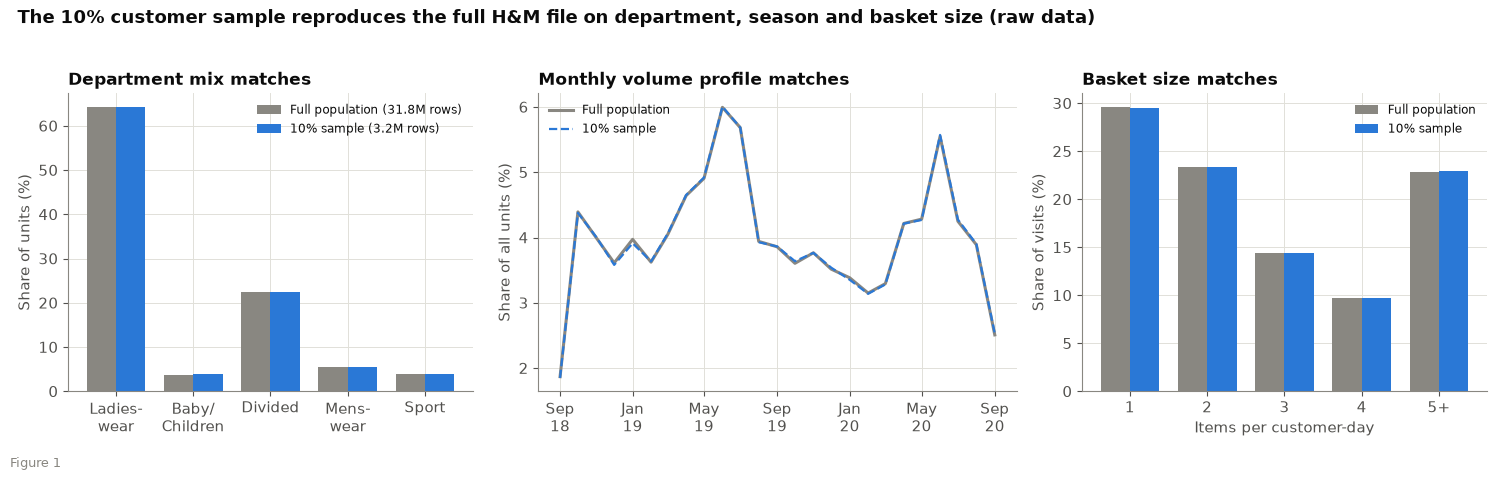

In [11]:
# Figure 1: representativeness at a glance (raw vs full population, and the shift caused by cleaning)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.1, 1.3, 1.1]})
# (a) department mix
d = dept_tab[["full (raw)", "sample (raw)"]].copy()
d = d.reindex(["Ladieswear", "Baby/Children", "Divided", "Menswear", "Sport"])
x = np.arange(len(d)); w = 0.38
ax[0].bar(x - w/2, d["full (raw)"] * 100, w, color=C["muted"], label="Full population (31.8M rows)")
ax[0].bar(x + w/2, d["sample (raw)"] * 100, w, color=C["blue"], label="10% sample (3.2M rows)")
ax[0].set_xticks(x); ax[0].set_xticklabels(["Ladies-\nwear", "Baby/\nChildren", "Divided", "Mens-\nwear", "Sport"])
ax[0].set_ylabel("Share of units (%)"); ax[0].set_title("Department mix matches"); ax[0].legend(fontsize=8.5)
# (b) monthly profile
ax[1].plot(pd.to_datetime(mon.index), mon["full raw"] * 100, color=C["muted"], lw=2.2, label="Full population")
ax[1].plot(pd.to_datetime(mon.index), mon["sample raw"] * 100, color=C["blue"], lw=1.6, ls="--", label="10% sample")
ax[1].set_ylabel("Share of all units (%)"); ax[1].set_title("Monthly volume profile matches"); ax[1].legend(fontsize=8.5)
ax[1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b\n%y")); ax[1].xaxis.set_major_locator(mpl.dates.MonthLocator(interval=4))
# (c) basket size
b = bs_tab.iloc[:5]
x = np.arange(len(b))
ax[2].bar(x - w/2, b["full (raw)"] * 100, w, color=C["muted"], label="Full population")
ax[2].bar(x + w/2, b["sample (raw)"] * 100, w, color=C["blue"], label="10% sample")
ax[2].set_xticks(x); ax[2].set_xticklabels(b.index); ax[2].set_xlabel("Items per customer-day"); ax[2].set_ylabel("Share of visits (%)")
ax[2].set_title("Basket size matches"); ax[2].legend(fontsize=8.5)
fig.suptitle("The 10% customer sample reproduces the full H&M file on department, season and basket size (raw data)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "fig01_representativeness")

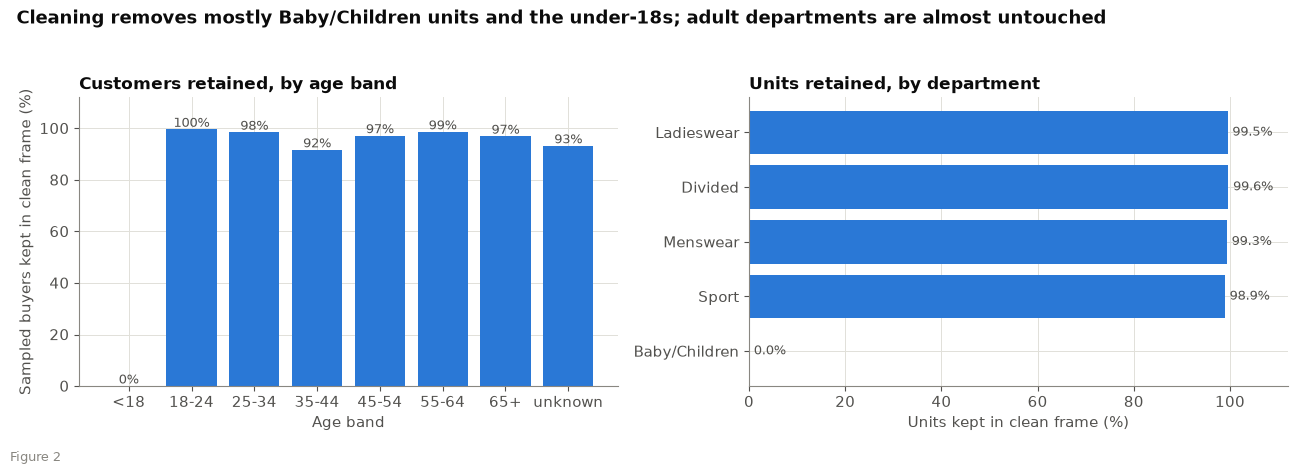

In [12]:
# Figure 2: what do OUR cleaning filters change? (who and what is dropped)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
raw_age = cust_s_c.groupby("age_band").size().reindex(BAND_ORDER).fillna(0)
kept_age = cust.groupby("age_band").size().reindex(BAND_ORDER).fillna(0)
ret = (kept_age / raw_age * 100)
ax[0].bar(range(len(ret)), ret, color=[C["red"] if b == "<18" else C["blue"] for b in ret.index])
for i, v in enumerate(ret): ax[0].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=C["ink2"])
ax[0].set_xticks(range(len(ret))); ax[0].set_xticklabels(ret.index); ax[0].set_ylim(0, 112)
ax[0].set_ylabel("Sampled buyers kept in clean frame (%)"); ax[0].set_xlabel("Age band"); ax[0].set_title("Customers retained, by age band")
# units dropped by department
dd = tx.article_id.map(art_idx.index_group_name).value_counts()
kept = lines.groupby("index_group_name").qty.sum()
dr = pd.DataFrame({"raw": dd, "kept": kept}).fillna(0); dr["share kept"] = dr.kept / dr.raw * 100
dr = dr.reindex(["Ladieswear", "Divided", "Menswear", "Sport", "Baby/Children"])
ax[1].barh(range(len(dr)), dr["share kept"], color=[C["blue"]] * 4 + [C["red"]])
for i, v in enumerate(dr["share kept"]): ax[1].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9, color=C["ink2"])
ax[1].set_yticks(range(len(dr))); ax[1].set_yticklabels(dr.index); ax[1].invert_yaxis(); ax[1].set_xlim(0, 112)
ax[1].set_xlabel("Units kept in clean frame (%)"); ax[1].set_title("Units retained, by department")
fig.suptitle("Cleaning removes mostly Baby/Children units and the under-18s; adult departments are almost untouched", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout(); save(fig, "fig02_cleaning_effect")
KEY["baby_units_share"] = float(dd["Baby/Children"] / dd.sum())

**Reading the checks.** The sample reproduces the full file closely on the dimensions the scoreboard tests, on both raw and cleaned data. The cleaned frame is a deliberate subset (adults, adult departments, apparel), so its shifts are the intended effect of scoping, not sampling error. The remaining bias checks (3.3) are about the population itself and about what the data cannot show.

### 3.3 Other bias checks: who is missing, who dominates, what changed in time

These checks ask whether the data can be trusted to represent *Westside's* shoppers, not only whether the sample represents H&M. They are run on the cleaned frame.

In [13]:
# (a) Is missing demographic information informative? (missing age / FN flag / club status vs behaviour)
rows = []
def mw(a, b):
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    cles = u.statistic / (len(a) * len(b))      # P(random a > random b)
    return u.pvalue, cles
for label, mask in [("age unknown", cust.age_band == "unknown"), ("FN flag missing/0", cust.FN == 0), ("club status UNKNOWN/PRE-CREATE", cust.club.isin(["UNKNOWN", "PRE-CREATE"]))]:
    a, b = cust.loc[mask, "n_visits"], cust.loc[~mask, "n_visits"]
    p, cles = mw(a, b)
    rows.append((label, int(mask.sum()), mask.mean(), a.median(), b.median(), a.mean(), b.mean(), cles, p))
miss = pd.DataFrame(rows, columns=["group", "customers", "share", "median visits (group)", "median visits (others)",
                                   "mean visits (group)", "mean visits (others)", "P(group > other)", "p-value"]).set_index("group")
display(miss)

# (b) Customer concentration (Lorenz / Gini) on cleaned units, compared with the full file's purchases-per-customer
u = np.sort(cust.units.to_numpy()); cum = np.cumsum(u) / u.sum(); lor_x = np.arange(1, len(u) + 1) / len(u)
gini = 1 - 2 * np.trapz(cum, lor_x) + 1 / len(u)
top10 = u[int(len(u) * 0.9):].sum() / u.sum(); top1 = u[int(len(u) * 0.99):].sum() / u.sum()
bottom50 = u[: int(len(u) * 0.5)].sum() / u.sum()
conc = pd.Series({"Gini of units per customer": gini, "top 1% of customers: share of units": top1,
                  "top 10% of customers: share of units": top10, "bottom 50% of customers: share of units": bottom50,
                  "customers with a single visit": (cust.n_visits == 1).mean(), "customers with >= 4 visits": (cust.n_visits >= 4).mean()})
display(conc.to_frame("value"))
KEY.update(gini=float(gini), top10_units=float(top10), top1_units=float(top1), bottom50_units=float(bottom50),
           one_visit_cust=float((cust.n_visits == 1).mean()))

,customers,share,median visits (group),median visits (others),mean visits (group),mean visits (others),P(group > other),p-value
group,,,,,,,,
age unknown,1494,0.011,1.000,3.000,3.029,6.743,0.344,0.000
FN flag missing/0,86072,0.650,2.000,4.000,5.743,8.481,0.404,0.000
club status UNKNOWN/PRE-CREATE,9161,0.069,1.000,3.000,2.072,7.045,0.277,0.000


,value
Gini of units per customer,0.642
top 1% of customers: share of units,0.115
top 10% of customers: share of units,0.480
bottom 50% of customers: share of units,0.084
customers with a single visit,0.320
customers with >= 4 visits,0.461


In [14]:
# (c) Time: volume and channel mix across the window (a structural break would bias a pooled model)
wk = lines[lines.wk_ok].groupby(["week", "index_group_name"]).qty.sum().unstack().fillna(0)
mon_ch = lines.assign(m=lines.t_dat.dt.to_period("M").dt.to_timestamp()).groupby(["m", "sales_channel_id"]).qty.sum().unstack().fillna(0)
ch2_share = mon_ch[2] / mon_ch.sum(axis=1)
pre, post = ch2_share[(ch2_share.index >= "2019-03-01") & (ch2_share.index < "2019-09-01")].mean(), ch2_share[(ch2_share.index >= "2020-03-01") & (ch2_share.index < "2020-09-01")].mean()
vol_pre = wk[(wk.index >= "2019-03-01") & (wk.index < "2019-09-01")].sum(axis=1).mean()
vol_post = wk[(wk.index >= "2020-03-01") & (wk.index < "2020-09-01")].sum(axis=1).mean()
print(f"channel-2 share of units, Mar-Aug 2019: {pre:.1%}  vs  Mar-Aug 2020: {post:.1%}")
print(f"mean weekly units, Mar-Aug 2019: {vol_pre:,.0f}  vs  Mar-Aug 2020: {vol_post:,.0f}  ({vol_post/vol_pre-1:+.1%})")
KEY.update(ch2_pre=float(pre), ch2_post=float(post), vol_2020_vs_2019=float(vol_post / vol_pre - 1))

channel-2 share of units, Mar-Aug 2019: 69.8%  vs  Mar-Aug 2020: 75.1%
mean weekly units, Mar-Aug 2019: 34,659  vs  Mar-Aug 2020: 30,128  (-13.1%)


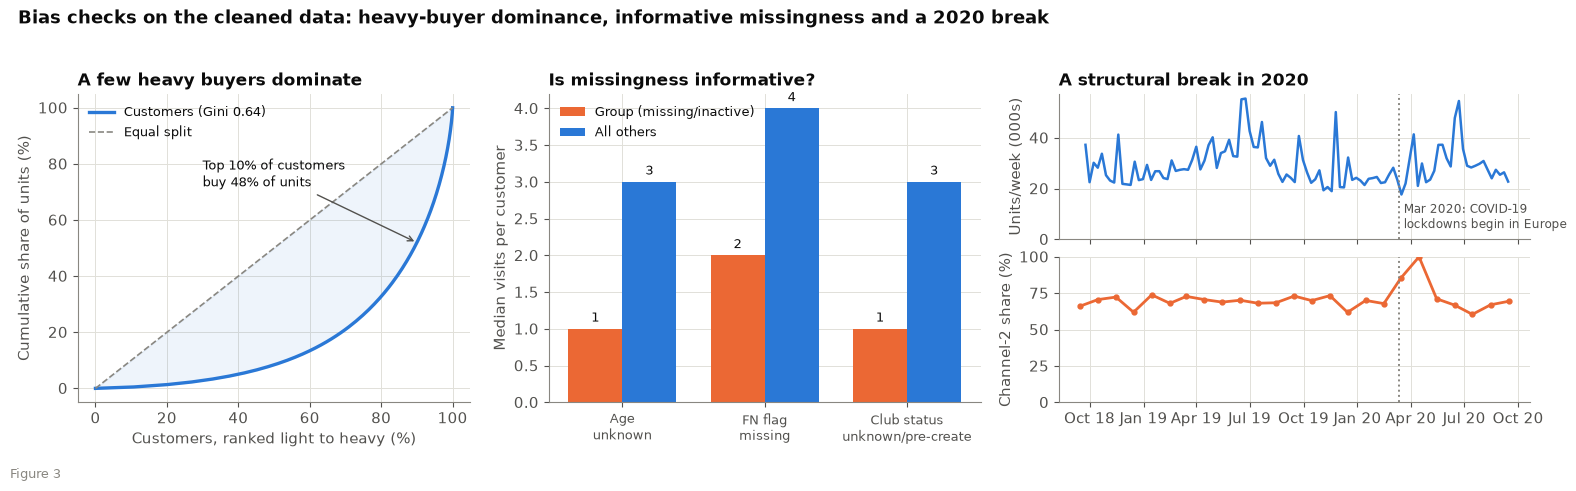

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.0, 1.1, 1.2]})
# (a) Lorenz
ax[0].plot(lor_x * 100, cum * 100, color=C["blue"], lw=2.4, label=f"Customers (Gini {gini:.2f})")
ax[0].plot([0, 100], [0, 100], color=C["muted"], lw=1.2, ls="--", label="Equal split")
ax[0].fill_between(lor_x * 100, cum * 100, lor_x * 100, color=C["blue"], alpha=0.08)
ax[0].annotate(f"Top 10% of customers\nbuy {top10:.0%} of units", xy=(90, cum[int(len(u) * .9)] * 100), xytext=(30, 72),
               arrowprops=dict(arrowstyle="->", color=C["ink2"]), fontsize=9.5)
ax[0].set_xlabel("Customers, ranked light to heavy (%)"); ax[0].set_ylabel("Cumulative share of units (%)")
ax[0].set_title("A few heavy buyers dominate"); ax[0].legend(loc="upper left", fontsize=9)
# (b) missingness informativeness
m2 = miss[["median visits (group)", "median visits (others)"]]
x = np.arange(len(m2)); w = 0.38
ax[1].bar(x - w/2, m2.iloc[:, 0], w, color=C["orange"], label="Group (missing/inactive)")
ax[1].bar(x + w/2, m2.iloc[:, 1], w, color=C["blue"], label="All others")
for i, (a, b) in enumerate(zip(m2.iloc[:, 0], m2.iloc[:, 1])):
    ax[1].text(i - w/2, a + .1, f"{a:.0f}", ha="center", fontsize=9); ax[1].text(i + w/2, b + .1, f"{b:.0f}", ha="center", fontsize=9)
ax[1].set_xticks(x); ax[1].set_xticklabels(["Age\nunknown", "FN flag\nmissing", "Club status\nunknown/pre-create"], fontsize=9)
ax[1].set_ylabel("Median visits per customer"); ax[1].set_title("Is missingness informative?"); ax[1].legend(fontsize=9)
# (c) weekly volume and channel mix, two stacked panels (no dual axis)
sub = ax[2].get_subplotspec().subgridspec(2, 1, hspace=0.12); ax[2].remove()
tot = wk.sum(axis=1)
a_top = fig.add_subplot(sub[0]); a_bot = fig.add_subplot(sub[1], sharex=a_top)
a_top.plot(tot.index, tot / 1000, color=C["blue"], lw=1.8); a_top.set_ylim(0); a_top.set_ylabel("Units/week (000s)")
a_bot.plot(ch2_share.index + pd.Timedelta(days=14), ch2_share * 100, color=C["orange"], lw=2, marker="o", ms=3.5)
a_bot.set_ylabel("Channel-2 share (%)"); a_bot.set_ylim(0, 100)
for a_ in (a_top, a_bot): a_.axvline(pd.Timestamp("2020-03-11"), color=C["muted"], ls=":", lw=1.4)
a_top.text(pd.Timestamp("2020-03-20"), tot.max() / 1000 * 0.08, "Mar 2020: COVID-19\nlockdowns begin in Europe", fontsize=8.5, color=C["ink2"])
plt.setp(a_top.get_xticklabels(), visible=False); a_bot.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
a_top.set_title("A structural break in 2020")
fig.suptitle("Bias checks on the cleaned data: heavy-buyer dominance, informative missingness and a 2020 break", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "fig03_bias_checks")

**Coverage gaps the sample cannot fix** (documented, not testable here)

| Gap | Why it matters for Westside | Mitigation |
|---|---|---|
| No gender or size field; department is the only proxy for who wears the item | Mirror advice and fairness checks by gender cannot be computed from purchases | Use department as a labelled proxy; fairness by gender is tested in M5 on volunteer data |
| H&M customers, European assortment, European age mix | Westside sells in India, with Indian wear and a different price ladder | Treat results as patterns to re-validate on Westside data (charter limitation) |
| No store or stock field | Stock-aware suggestions and transfers cannot be learned here | Simulated in M6 (charter) |
| Price is normalised | No rupee claims | Relative price only |
| `sales_channel_id` unlabelled | We cannot tell which channel is in-store | Do not draw in-store conclusions from channel |
| Purchases only: no browsing, no returns | A purchase is a weak proxy for liking an item | Returns and try-on signals come from the mirror itself (charter) |

## 4. Distributions

How big are baskets, how often do people shop, who are they, and what do items cost? All on the cleaned frame.

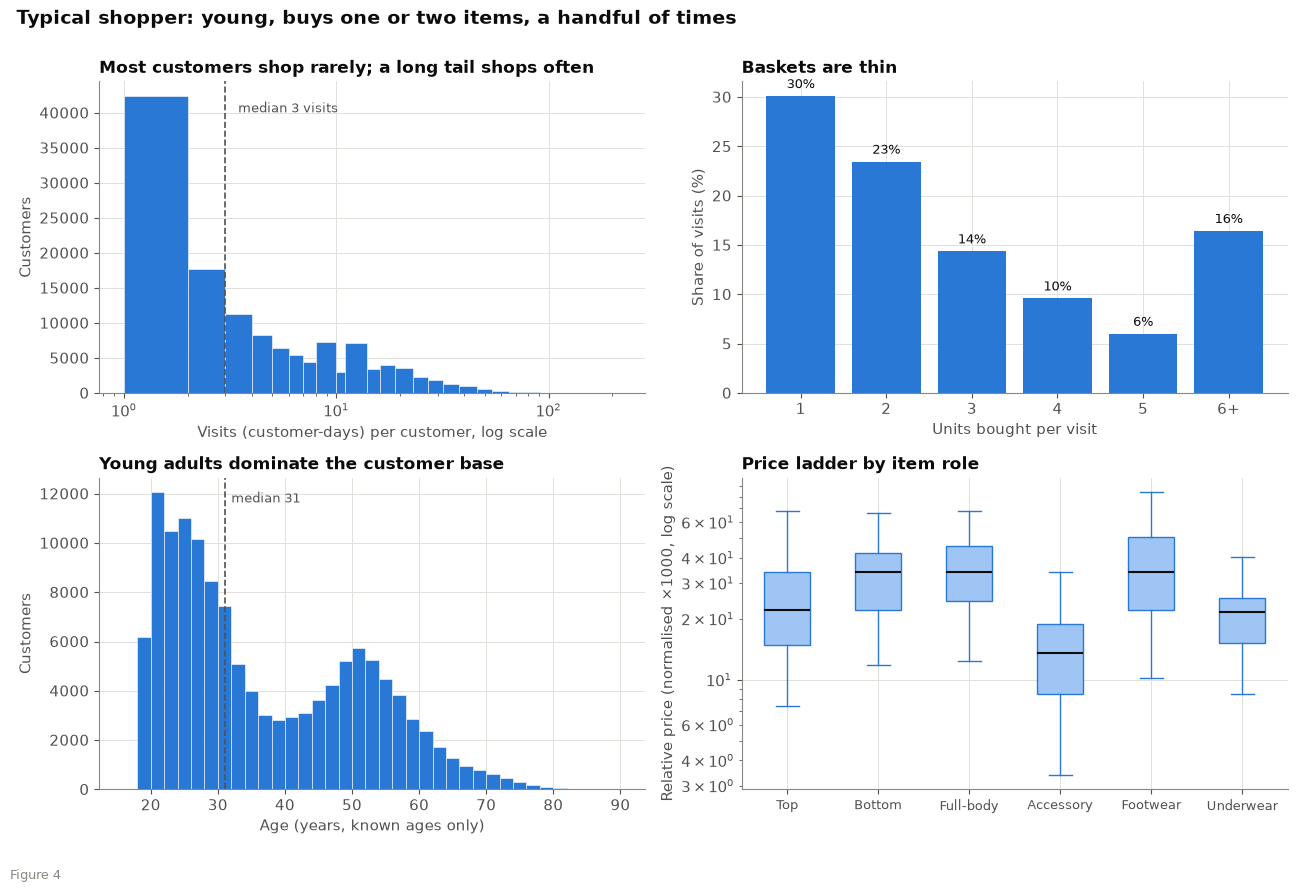

,visits per customer,units per visit,age
count,"132,435.000","887,485.000","130,941.000"
mean,6.700,3.460,36.400
std,9.540,3.550,14.290
min,1.000,1.000,18.000
25%,1.000,1.000,24.000
50%,3.000,2.000,31.000
75%,8.000,4.000,49.000
max,217.000,220.000,90.000


In [16]:
def ratio_ci(cust_codes, num, den, n_boot=300, seed=SEED):
    # Cluster bootstrap by customer for sum(num)/sum(den): visits of one customer are not independent.
    df = pd.DataFrame({"c": np.asarray(cust_codes), "n": np.asarray(num, float), "d": np.asarray(den, float)}).groupby("c").sum()
    n, d = df.n.to_numpy(), df.d.to_numpy(); m = len(df); r = np.random.default_rng(seed)
    bs = np.empty(n_boot)
    for i in range(n_boot):
        j = r.integers(0, m, m); bs[i] = n[j].sum() / d[j].sum()
    return n.sum() / d.sum(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

fig, ax = plt.subplots(2, 2, figsize=(13, 8.4))
# (a) visits per customer
bins = np.unique(np.round(np.logspace(0, np.log10(cust.n_visits.max() + 1), 32)))
ax[0, 0].hist(cust.n_visits, bins=bins, color=C["blue"], edgecolor="white", lw=0.4)
ax[0, 0].set_xscale("log"); ax[0, 0].axvline(cust.n_visits.median(), color=C["ink2"], ls="--", lw=1.2)
ax[0, 0].text(cust.n_visits.median() * 1.15, ax[0, 0].get_ylim()[1] * 0.9, f"median {cust.n_visits.median():.0f} visits", fontsize=9.5, color=C["ink2"])
ax[0, 0].set_xlabel("Visits (customer-days) per customer, log scale"); ax[0, 0].set_ylabel("Customers")
ax[0, 0].set_title("Most customers shop rarely; a long tail shops often")
# (b) units per visit
ub = visits.units.clip(upper=6).value_counts(normalize=True).sort_index() * 100
ax[0, 1].bar(range(len(ub)), ub.values, color=C["blue"])
for i, v in enumerate(ub.values): ax[0, 1].text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9.5)
ax[0, 1].set_xticks(range(len(ub))); ax[0, 1].set_xticklabels([str(int(i)) if i < 6 else "6+" for i in ub.index])
ax[0, 1].set_xlabel("Units bought per visit"); ax[0, 1].set_ylabel("Share of visits (%)"); ax[0, 1].set_title("Baskets are thin")
# (c) age
ages = cust.age_clean.dropna()
ax[1, 0].hist(ages, bins=np.arange(16, 92, 2), color=C["blue"], edgecolor="white", lw=0.4)
ax[1, 0].axvline(ages.median(), color=C["ink2"], ls="--", lw=1.2); ax[1, 0].text(ages.median() + 1, ax[1, 0].get_ylim()[1] * 0.92, f"median {ages.median():.0f}", fontsize=9.5, color=C["ink2"])
ax[1, 0].set_xlabel("Age (years, known ages only)"); ax[1, 0].set_ylabel("Customers"); ax[1, 0].set_title("Young adults dominate the customer base")
# (d) price by role
order = ["Top", "Bottom", "Full-body", "Accessory", "Footwear", "Underwear"]
samp = lines.sample(400_000, random_state=SEED)
data_ = [samp.loc[samp.role == r_, "price"].to_numpy() * 1000 for r_ in order]
ax[1, 1].boxplot(data_, whis=(5, 95), showfliers=False, patch_artist=True, medianprops=dict(color=C["ink"], lw=1.5),
                 boxprops=dict(facecolor="#9ec5f4", edgecolor=C["blue"]), whiskerprops=dict(color=C["blue"]), capprops=dict(color=C["blue"]))
ax[1, 1].set_yscale("log"); ax[1, 1].set_xticklabels(order, fontsize=9.5)
ax[1, 1].set_ylabel("Relative price (normalised ×1000, log scale)"); ax[1, 1].set_title("Price ladder by item role")
fig.suptitle("Typical shopper: young, buys one or two items, a handful of times", x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig04_distributions")
desc = pd.DataFrame({"visits per customer": cust.n_visits.describe(), "units per visit": visits.units.describe(), "age": ages.describe()})
display(desc.round(2))
KEY.update(median_visits=float(cust.n_visits.median()), mean_units_visit=float(visits.units.mean()), median_age=float(ages.median()))

**So what.** Half of customers buy on only a few days and the basket is small. A mirror is used at the moment of a visit, so the typical interaction has little history behind it and one or two items in hand. That affects how much a personalised model can know at the mirror, tested next.

## 5. Relationships: baskets, history signal and complementary items

### 5.1 H1: How thin are the baskets, and is the outfit incomplete?

single-unit visits: 30.1% (95% CI 30.0%-30.3%)
visits with a top AND a bottom: 22.2% (95% CI 22.1%-22.4%)


,share of garment visits
Complete (top+bottom or full-body),0.450
Top only,0.378
Bottom only,0.172


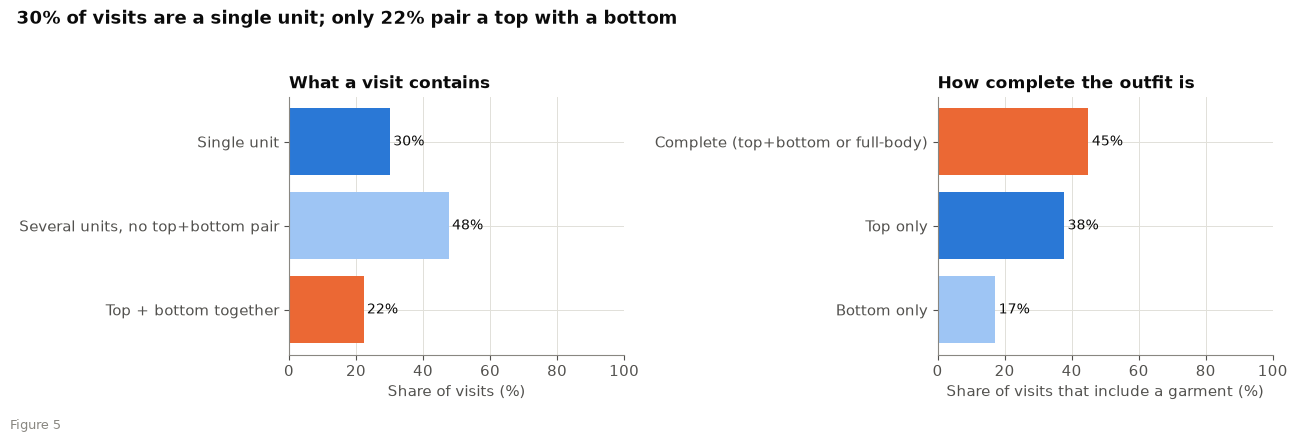

In [17]:
# Mutually exclusive visit types
vt = np.select([visits.pair, visits.single], ["Top + bottom together", "Single unit"], default="Several units, no top+bottom pair")
vt = pd.Series(vt, index=visits.index)
p_single, lo_s, hi_s = ratio_ci(visits.cust, visits.single, np.ones(len(visits)))
p_pair, lo_p, hi_p = ratio_ci(visits.cust, visits.pair, np.ones(len(visits)))
# Among visits that contain any garment, how complete is the outfit?
g = visits[visits.has_top | visits.has_bottom | visits.has_full]
comp = np.select([g.has_full | (g.has_top & g.has_bottom), g.has_top & ~g.has_bottom, g.has_bottom & ~g.has_top],
                 ["Complete (top+bottom or full-body)", "Top only", "Bottom only"], default="Other")
comp = pd.Series(comp).value_counts(normalize=True)
print(f"single-unit visits: {p_single:.1%} (95% CI {lo_s:.1%}-{hi_s:.1%})")
print(f"visits with a top AND a bottom: {p_pair:.1%} (95% CI {lo_p:.1%}-{hi_p:.1%})")
display(comp.to_frame("share of garment visits"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1, 1]})
v = vt.value_counts(normalize=True).reindex(["Single unit", "Several units, no top+bottom pair", "Top + bottom together"]) * 100
ax[0].barh(range(3), v.values, color=[C["blue"], "#9ec5f4", C["orange"]])
for i, x_ in enumerate(v.values): ax[0].text(x_ + 1, i, f"{x_:.0f}%", va="center", fontsize=10)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(v.index); ax[0].invert_yaxis(); ax[0].set_xlim(0, 100)
ax[0].set_xlabel("Share of visits (%)"); ax[0].set_title("What a visit contains")
c2 = comp.reindex(["Complete (top+bottom or full-body)", "Top only", "Bottom only"]).fillna(0) * 100
ax[1].barh(range(3), c2.values, color=[C["orange"], C["blue"], "#9ec5f4"])
for i, x_ in enumerate(c2.values): ax[1].text(x_ + 1, i, f"{x_:.0f}%", va="center", fontsize=10)
ax[1].set_yticks(range(3)); ax[1].set_yticklabels(c2.index); ax[1].invert_yaxis(); ax[1].set_xlim(0, 100)
ax[1].set_xlabel("Share of visits that include a garment (%)"); ax[1].set_title("How complete the outfit is")
fig.suptitle(f"{p_single:.0%} of visits are a single unit; only {p_pair:.0%} pair a top with a bottom", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout(); save(fig, "fig05_basket_composition")
KEY.update(p_single=float(p_single), p_single_lo=float(lo_s), p_single_hi=float(hi_s), p_pair=float(p_pair), p_pair_lo=float(lo_p), p_pair_hi=float(hi_p),
           top_only=float(comp.get("Top only", 0)), bottom_only=float(comp.get("Bottom only", 0)), complete=float(comp.get("Complete (top+bottom or full-body)", 0)))

### 5.2 H2: Does purchase history predict the next purchase?

For every item bought after a customer's first visit, we ask: had this customer already bought the same article, product type, colour or department before that day? The **random baseline** shuffles the attribute among items bought in the *same week*, so it keeps seasonality and popularity but breaks the link to the customer. A ratio well above 1 means history carries information that a best-seller list cannot.

,hit rate (history),"hit rate (random, same week)",ratio
attribute,,,
Exact article (repeat purchase),0.054,0.003,19.173
Product type,0.598,0.474,1.262
Colour (master),0.765,0.717,1.067
Department,0.921,0.876,1.052


items evaluated: 2,360,065  (4s)


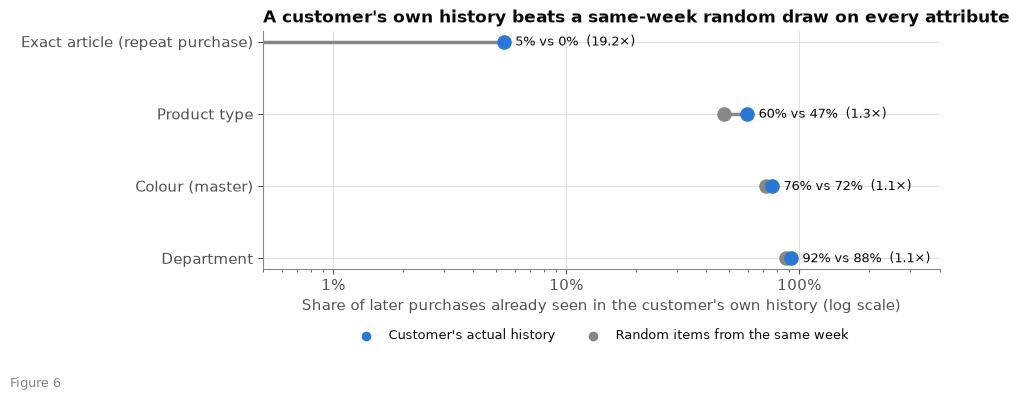

In [18]:
day = lines.t_dat.values.astype("datetime64[D]").astype(np.int64)
cust_a = lines.cust.to_numpy().astype(np.int64)
first_day = pd.Series(day).groupby(cust_a).transform("min").to_numpy()
elig = day > first_day                              # items bought after the customer's first day
week_idx = lines.groupby("week").indices            # week -> row positions

def hist_hit_rates(col, n_shuf=3):
    code_ = pd.factorize(lines[col])[0].astype(np.int64); K = int(code_.max()) + 1
    fs = pd.Series(day).groupby(cust_a * K + code_).min()     # first day the customer bought this attribute value
    def hit(codes_): return fs.reindex(cust_a * K + codes_).to_numpy() < day
    real = hit(code_)[elig].mean()
    base = []
    for _ in range(n_shuf):
        sh = code_.copy()
        for w, idx in week_idx.items(): sh[idx] = rng.permutation(code_[idx])
        base.append(hit(sh)[elig].mean())
    return real, float(np.mean(base))

t = time.time()
hist = pd.DataFrame([(name, *hist_hit_rates(col)) for name, col in [
    ("Exact article (repeat purchase)", "article_id"), ("Product type", "product_type_name"),
    ("Colour (master)", "perceived_colour_master_name"), ("Department", "index_group_name")]],
    columns=["attribute", "hit rate (history)", "hit rate (random, same week)"]).set_index("attribute")
hist["ratio"] = hist.iloc[:, 0] / hist.iloc[:, 1]
display(hist); print(f"items evaluated: {int(elig.sum()):,}  ({time.time()-t:.0f}s)")
KEY["hist"] = {k: dict(real=float(r["hit rate (history)"]), base=float(r["hit rate (random, same week)"]), ratio=float(r["ratio"])) for k, r in hist.iterrows()}
KEY["items_eval"] = int(elig.sum())

fig, ax = plt.subplots(figsize=(9.5, 3.8))
y = np.arange(len(hist))[::-1]
for yi, (k, r) in zip(y, hist.iterrows()):
    ax.plot([r.iloc[1] * 100, r.iloc[0] * 100], [yi, yi], color=C["muted"], lw=2.5, zorder=1)
    ax.scatter(r.iloc[1] * 100, yi, s=90, color=C["muted"], zorder=2); ax.scatter(r.iloc[0] * 100, yi, s=90, color=C["blue"], zorder=2)
    ax.text(r.iloc[0] * 100 * 1.12, yi, f"{r.iloc[0]:.0%} vs {r.iloc[1]:.0%}  ({r['ratio']:.1f}×)", va="center", fontsize=9.5)
ax.set_yticks(y); ax.set_yticklabels(hist.index); ax.set_xscale("log"); ax.set_xlim(0.5, 400)
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}%")); ax.set_xlabel("Share of later purchases already seen in the customer's own history (log scale)")
ax.scatter([], [], color=C["blue"], label="Customer's actual history"); ax.scatter([], [], color=C["muted"], label="Random items from the same week"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9)
ax.set_title("A customer's own history beats a same-week random draw on every attribute")
fig.tight_layout(); save(fig, "fig06_history_signal")

**So what.** Where the ratio is far above 1, a model that reads the member's history has real information to work with that a best-seller list lacks. Where the baseline hit rate is already high (department, product type), the gain over chance is small in absolute terms because the choice set is small; the useful signal is at the finer levels (colour, exact article).

### 5.3 H3: Which product types are bought together?

Raw co-occurrence is misleading: big baskets contain everything. The **adjusted lift** divides the observed number of visits containing both types by the number expected when the same items are shuffled among visits of the same size and week (average of 5 shuffles). Lift above 1 means the pair is bought together more than basket size and season explain. The unit is the distinct product type within a visit, and only visits with two or more distinct types are used.

In [19]:
t = time.time()
# Unit of analysis: distinct product types within a visit (a visit with three T-shirts counts T-shirt once),
# so the shuffle keeps each visit's number of distinct types and the null is not distorted by repeated types.
L2 = lines[["vid", "week", "product_type_name", "role"]].drop_duplicates(["vid", "product_type_name"]).reset_index(drop=True)
L2["vsize"] = L2.groupby("vid").vid.transform("size")
L2 = L2[L2.vsize >= 2].reset_index(drop=True)
ptc, ptu = pd.factorize(L2.product_type_name)
L2["ptc"] = ptc
vis_per_type = L2[["vid", "ptc"]].drop_duplicates().ptc.value_counts()
topK = vis_per_type.index[:16].to_numpy(); K = len(topK)
type_role = L2.groupby("ptc").role.agg(lambda s: s.value_counts().index[0])
role_order = {"Top": 0, "Bottom": 1, "Full-body": 2, "Footwear": 3, "Accessory": 4}
topK = sorted(topK, key=lambda t_: (role_order.get(type_role[t_], 9), -vis_per_type[t_]))
pos = {t_: i for i, t_ in enumerate(topK)}
vcode = pd.factorize(L2.vid)[0]; nv = vcode.max() + 1

def cooc(types_):
    m = np.isin(types_, topK)
    X = sparse.coo_matrix((np.ones(m.sum(), np.float32), (vcode[m], np.array([pos[t_] for t_ in types_[m]]))), shape=(nv, K)).tocsr()
    X.data[:] = 1
    M = (X.T @ X).toarray(); np.fill_diagonal(M, 0); return M

obs = cooc(ptc)
strata = L2.assign(vb=L2.vsize.clip(upper=6)).groupby(["week", "vb"]).indices
shuf = []
for _ in range(5):
    sh = ptc.copy()
    for idx in strata.values(): sh[idx] = rng.permutation(ptc[idx])
    shuf.append(cooc(sh))
exp_ = np.mean(shuf, axis=0)
lift = np.where(exp_ > 0, obs / np.maximum(exp_, 1e-9), np.nan)
names = [ptu[t_] for t_ in topK]; roles_ = [type_role[t_] for t_ in topK]
lift_df = pd.DataFrame(lift, index=names, columns=names); obs_df = pd.DataFrame(obs, index=names, columns=names)

tb = [(i, j) for i in range(K) for j in range(i + 1, K) if {roles_[i], roles_[j]} == {"Top", "Bottom"}]
tt = [(i, j) for i in range(K) for j in range(i + 1, K) if roles_[i] == roles_[j] == "Top"]
lift_tb = np.array([lift[i, j] for i, j in tb]); lift_tt = np.array([lift[i, j] for i, j in tt])
print(f"top x bottom pairs: n={len(tb)}, median adjusted lift {np.median(lift_tb):.2f}, share with lift>=1.2: {(lift_tb>=1.2).mean():.0%}")
print(f"top x top pairs   : n={len(tt)}, median adjusted lift {np.median(lift_tt):.2f}")
pairs = pd.DataFrame([(names[i], names[j], roles_[i] + " x " + roles_[j], lift[i, j], int(obs[i, j])) for i in range(K) for j in range(i + 1, K)],
                     columns=["type A", "type B", "roles", "adjusted lift", "visits together"])
display(pairs[pairs["visits together"] >= 200].sort_values("adjusted lift", ascending=False).head(10).reset_index(drop=True))
KEY.update(lift_tb_median=float(np.median(lift_tb)), lift_tb_n=len(tb), lift_tb_share12=float((lift_tb >= 1.2).mean()), lift_tt_median=float(np.median(lift_tt)),
           top_pairs=pairs[pairs["visits together"] >= 200].sort_values("adjusted lift", ascending=False).head(5).values.tolist())
print(f"({time.time()-t:.0f}s)")

top x bottom pairs: n=28, median adjusted lift 1.35, share with lift>=1.2: 68%
top x top pairs   : n=21, median adjusted lift 1.36


,type A,type B,roles,adjusted lift,visits together
0,Bikini top,Swimwear bottom,Swimwear x Swimwear,7.872,45925
1,Bra,Underwear bottom,Underwear x Underwear,5.024,26299
2,Leggings/Tights,Bra,Bottom x Underwear,2.059,8470
3,Blouse,Shirt,Top x Top,2.014,12094
4,Skirt,Dress,Bottom x Full-body,1.860,19211
5,Vest top,Shorts,Top x Bottom,1.818,14226
6,Vest top,Leggings/Tights,Top x Bottom,1.801,8078
7,Sweater,Trousers,Top x Bottom,1.783,46643
8,T-shirt,Shorts,Top x Bottom,1.731,15680
9,Blouse,Dress,Top x Full-body,1.687,24806


(2s)


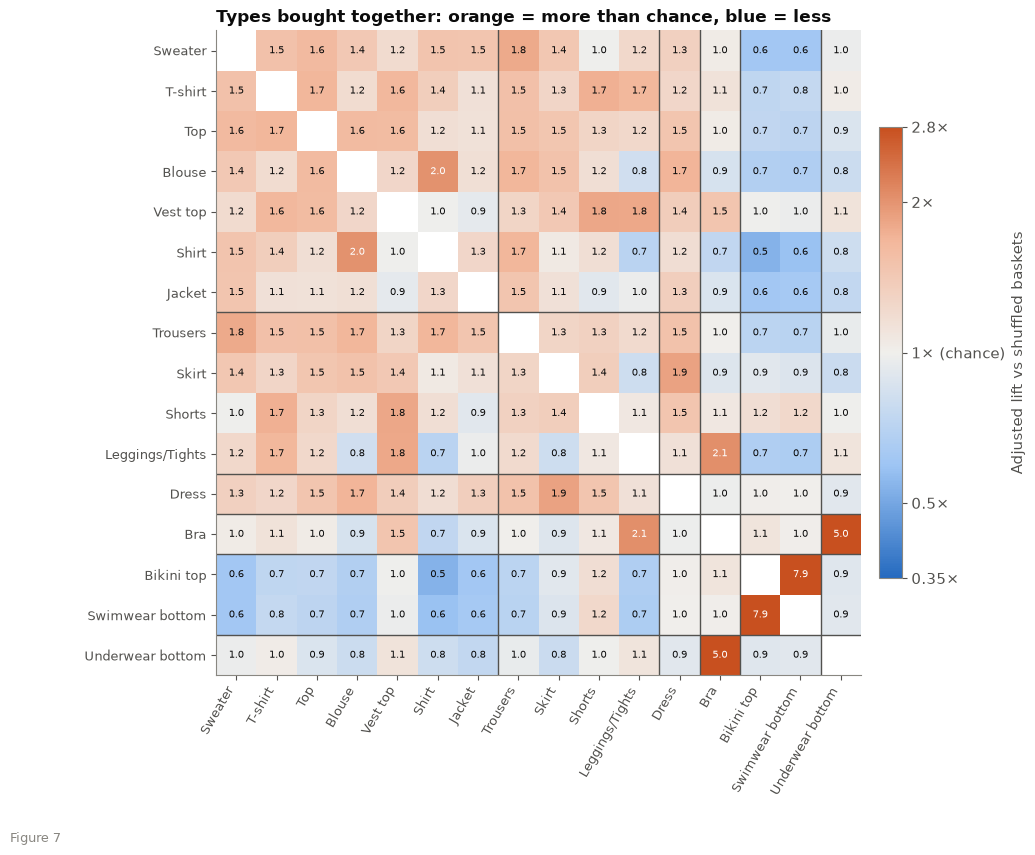

In [20]:
fig, ax = plt.subplots(figsize=(10.5, 8.2))
Z = np.log2(np.where(np.isnan(lift), 1, lift)); np.fill_diagonal(Z, np.nan)
im = ax.imshow(Z, cmap=DIV, vmin=-1.5, vmax=1.5)
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels([f"{n}" for n in names], rotation=60, ha="right", fontsize=9); ax.set_yticklabels(names, fontsize=9)
ax.grid(False)
for i in range(K):
    for j in range(K):
        if i != j and not np.isnan(lift[i, j]): ax.text(j, i, f"{lift[i, j]:.1f}", ha="center", va="center", fontsize=7.5, color=C["ink"] if abs(Z[i, j]) < 1.0 else "white")
# role separators
cuts = [i for i in range(1, K) if roles_[i] != roles_[i - 1]]
for c_ in cuts: ax.axhline(c_ - .5, color=C["ink2"], lw=1); ax.axvline(c_ - .5, color=C["ink2"], lw=1)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02); cb.set_ticks([-1.5, -1, 0, 1, 1.5]); cb.set_ticklabels(["0.35×", "0.5×", "1× (chance)", "2×", "2.8×"])
cb.set_label("Adjusted lift vs shuffled baskets")
ax.set_title("Types bought together: orange = more than chance, blue = less", fontsize=12)
fig.tight_layout(); save(fig, "fig07_pair_lift")

**So what.** This is the evidence base for the outfit matcher. Pairs with high adjusted lift are candidate "goes with" rules the model can learn from purchases alone. Pairs of the *same* role (two tops) show whether shoppers buy alternatives or duplicates; an outfit model should not suggest them together unless the lift supports it.

## 6. Demand over time: seasonality, concentration and churn (H4)

Weekly analyses use complete weeks only. Because the sample holds 10% of customers, weekly counts for a single article are noisy; a **split-half ceiling** (two random halves of the customers compared in the same week) shows how much overlap sampling noise alone would allow.

In [21]:
lw = lines[lines.wk_ok]
weeks = sorted(lw.week.unique())
aw = lw.groupby(["week", "article_id"]).qty.sum()
wk_ser = {w: s.droplevel(0).sort_values(ascending=False) for w, s in aw.groupby(level=0)}

# (a) concentration of units over articles
au = lines.groupby("article_id").qty.sum().sort_values(ascending=False); cum_a = au.cumsum() / au.sum()
n_art = len(au); top1_art = cum_a.iloc[int(n_art * 0.01) - 1]; top10_art = cum_a.iloc[int(n_art * 0.10) - 1]
n50 = int((cum_a < 0.5).sum() + 1)
print(f"articles sold: {n_art:,} | top 1% hold {top1_art:.1%} of units | top 10% hold {top10_art:.1%} | {n50:,} articles ({n50/n_art:.1%}) make half of units")

# (b) coverage of next week's units by last week's top-K
Ks = [12, 100, 500]
cov = {k: [] for k in Ks}
for a_, b_ in zip(weeks[:-1], weeks[1:]):
    prev, cur = wk_ser[a_], wk_ser[b_]
    for k in Ks: cov[k].append(cur.reindex(prev.index[:k]).fillna(0).sum() / cur.sum())
cov = pd.DataFrame(cov, index=weeks[1:])

# (c) overlap of the top-100 between weeks, by lag; split-half noise ceiling
def jac(a, b): a, b = set(a), set(b); return len(a & b) / len(a | b)
jl = {}
for lag in [1, 4, 13, 52]:
    jl[lag] = np.mean([jac(wk_ser[weeks[i]].index[:100], wk_ser[weeks[i + lag]].index[:100]) for i in range(len(weeks) - lag)])
half = pd.Series(rng.integers(0, 2, lines.cust.max() + 1), name="half")
lwh = lw.assign(h=half.reindex(lw.cust).to_numpy())
cei = []
for w, g in lwh.groupby("week"):
    a_ = g[g.h == 0].groupby("article_id").qty.sum().nlargest(100).index; b_ = g[g.h == 1].groupby("article_id").qty.sum().nlargest(100).index
    cei.append(jac(a_, b_))
ceiling = float(np.mean(cei))
print("top-100 Jaccard by lag (weeks):", {k: round(v, 3) for k, v in jl.items()}, "| same-week split-half ceiling:", round(ceiling, 3))
print("last-week top-K covers next week's units (mean):", {k: f"{cov[k].mean():.1%}" for k in Ks})

# (d) novelty and lifespan
first_wk = lw.groupby("article_id").week.min(); last_wk = lw.groupby("article_id").week.max()
lw2 = lw.assign(age_w=((lw.week - lw.article_id.map(first_wk)).dt.days // 7))
nov = (lw2[lw2.age_w <= 8].groupby("week").qty.sum() / lw2.groupby("week").qty.sum()).reindex(weeks).fillna(0)
nov = nov.iloc[26:]
art_tot = lw.groupby("article_id").qty.sum()
cand = first_wk[(first_wk >= weeks[8]) & (first_wk <= weeks[52]) & (art_tot.reindex(first_wk.index) >= 5)]
span = ((last_wk.reindex(cand.index) - cand).dt.days // 7)
print(f"articles launched in weeks 9-53 with >=5 units: {len(cand):,} | median span {span.median():.0f} weeks | still selling 26+ weeks later: {(span>=26).mean():.0%}")
print(f"share of weekly units from articles first sold <= 8 weeks earlier (weeks 27+): mean {nov.mean():.1%}")
KEY.update(top1_art=float(top1_art), top10_art=float(top10_art), n_art=int(n_art), n50=n50, cov12=float(cov[12].mean()), cov100=float(cov[100].mean()), cov500=float(cov[500].mean()),
           jac1=float(jl[1]), jac4=float(jl[4]), jac13=float(jl[13]), jac52=float(jl[52]), jac_ceiling=ceiling, novelty=float(nov.mean()), span_med=float(span.median()), span26=float((span >= 26).mean()))

articles sold: 62,428 | top 1% hold 14.4% of units | top 10% hold 50.0% | 6,241 articles (10.0%) make half of units


top-100 Jaccard by lag (weeks): {1: np.float64(0.289), 4: np.float64(0.133), 13: np.float64(0.046), 52: np.float64(0.047)} | same-week split-half ceiling: 0.371
last-week top-K covers next week's units (mean): {12: '1.6%', 100: '8.4%', 500: '24.6%'}


articles launched in weeks 9-53 with >=5 units: 19,670 | median span 39 weeks | still selling 26+ weeks later: 68%
share of weekly units from articles first sold <= 8 weeks earlier (weeks 27+): mean 39.0%


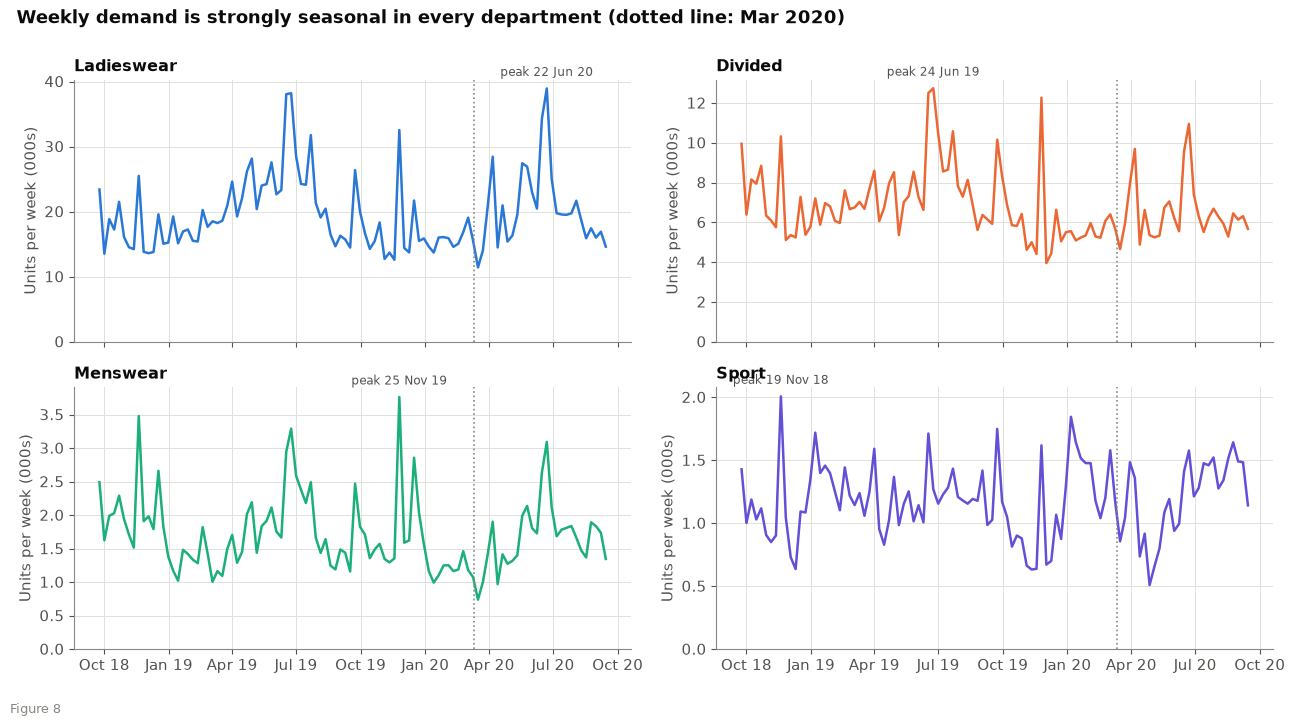

In [22]:
# Weekly units by department: small multiples, one colour per department (own y-scale; shape is what matters)
fig, axs = plt.subplots(2, 2, figsize=(13, 6.8), sharex=True)
for a_, d_ in zip(axs.ravel(), ["Ladieswear", "Divided", "Menswear", "Sport"]):
    s = wk[d_] / 1000
    a_.plot(s.index, s.values, color=DEPT_COL[d_], lw=1.8); a_.set_ylim(0); a_.set_title(d_, fontsize=11.5); a_.set_ylabel("Units per week (000s)")
    pk = s.idxmax(); a_.annotate(f"peak {pk:%d %b %y}", xy=(pk, s.max()), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=C["ink2"])
    a_.axvline(pd.Timestamp("2020-03-11"), color=C["muted"], ls=":", lw=1.2)
    a_.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
fig.suptitle("Weekly demand is strongly seasonal in every department (dotted line: Mar 2020)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "fig08_weekly_by_dept")
mw_ = wk["Menswear"]; KEY["menswear_cv"] = float(mw_.std() / mw_.mean()); KEY["all_cv"] = float(wk.sum(axis=1).std() / wk.sum(axis=1).mean())
KEY["menswear_share_units"] = float(lines.loc[lines.index_group_name == "Menswear", "qty"].sum() / lines.qty.sum())

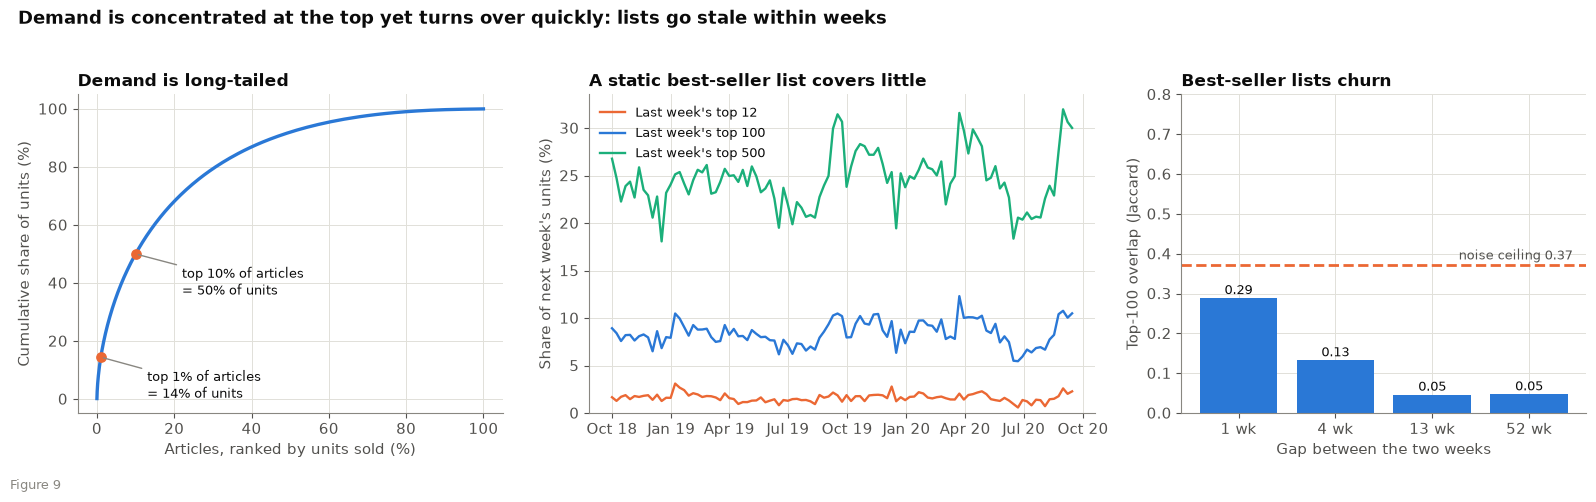

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.05, 1.25, 1]})
# (a) Pareto
xs = np.arange(1, n_art + 1) / n_art * 100
ax[0].plot(xs, cum_a.values * 100, color=C["blue"], lw=2.4)
for p_, v_ in [(1, top1_art), (10, top10_art)]:
    ax[0].scatter([p_], [v_ * 100], color=C["orange"], zorder=3, s=45); ax[0].annotate(f"top {p_}% of articles\n= {v_:.0%} of units", xy=(p_, v_ * 100), xytext=(p_ + 12, v_ * 100 - 14), fontsize=9.5, arrowprops=dict(arrowstyle="-", color=C["muted"]))
ax[0].set_xlabel("Articles, ranked by units sold (%)"); ax[0].set_ylabel("Cumulative share of units (%)"); ax[0].set_title("Demand is long-tailed")
# (b) coverage over time
for k, col, ls in [(12, C["orange"], "-"), (100, C["blue"], "-"), (500, C["aqua"], "-")]:
    ax[1].plot(cov.index, cov[k] * 100, color=col, lw=1.7, label=f"Last week's top {k}")
ax[1].set_ylabel("Share of next week's units (%)"); ax[1].set_ylim(0); ax[1].legend(fontsize=9, loc="upper left"); ax[1].set_title("A static best-seller list covers little")
ax[1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
# (c) overlap by lag with ceiling
lags = list(jl.keys()); ax[2].bar(range(len(lags)), [jl[k] for k in lags], color=C["blue"])
ax[2].axhline(ceiling, color=C["orange"], lw=2, ls="--"); ax[2].text(3.45, ceiling + 0.015, f"noise ceiling {ceiling:.2f}", ha="right", fontsize=9.5, color=C["ink2"])
for i, k in enumerate(lags): ax[2].text(i, jl[k] + 0.01, f"{jl[k]:.2f}", ha="center", fontsize=9.5)
ax[2].set_xticks(range(len(lags))); ax[2].set_xticklabels([f"{k} wk" for k in lags]); ax[2].set_ylim(0, 0.8)
ax[2].set_xlabel("Gap between the two weeks"); ax[2].set_ylabel("Top-100 overlap (Jaccard)"); ax[2].set_title("Best-seller lists churn")
fig.suptitle("Demand is concentrated at the top yet turns over quickly: lists go stale within weeks", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "fig09_demand_concentration_churn")

**So what.** The charter's best-seller baseline is the bar the recommender must clear. This section shows how hard that bar is on a time-split: the share of next week's units that last week's top articles capture, and how fast the list changes. It also tells M4 that the weekly forecast must handle new articles that have no history.

## 7. Segments: age, channel, colour, and a proxy for the target group

### 7.1 H5: Do segments differ?

In [24]:
# (a) department mix by age band (units)
au_ = lines.assign(age_band=lines.cust.map(cust_s_c.age_band)).groupby(["age_band", "index_group_name"]).qty.sum().unstack().fillna(0).reindex(BAND_ORDER[1:])
au_ = au_[["Ladieswear", "Divided", "Menswear", "Sport"]]
chi2, p_chi, dof, _ = stats.chi2_contingency(au_.values)
cramer = math.sqrt(chi2 / (au_.values.sum() * (min(au_.shape) - 1)))
print(f"age band x department (known ages): chi2={chi2:,.0f}, dof={dof}, Cramer's V={cramer:.3f}")
mix = au_.div(au_.sum(axis=1), axis=0)

# (b) basket behaviour by age band with cluster-bootstrap CIs
rows = []
for b_ in BAND_ORDER[1:]:
    v_ = visits[visits.age_band == b_]
    s_, sl, sh = ratio_ci(v_.cust, v_.single, np.ones(len(v_)))
    u_, ul, uh = ratio_ci(v_.cust, v_.units, np.ones(len(v_)))
    rows.append((b_, v_.cust.nunique(), len(v_), s_, sl, sh, u_, ul, uh))
seg = pd.DataFrame(rows, columns=["age band", "customers", "visits", "single share", "s lo", "s hi", "units/visit", "u lo", "u hi"]).set_index("age band")
display(seg.round(3))
big = seg[seg.customers >= THR["H5_min_customers"]]
gap_single = float(big["single share"].max() - big["single share"].min())
print(f"single-unit share gap across age bands with >= {THR['H5_min_customers']} customers: {gap_single*100:.1f} points ({big['single share'].idxmin()} vs {big['single share'].idxmax()})")

# (c) channel and department of the visit
rows = []
for name, col in [("Channel", "channel"), ("Visit department", "dept")]:
    for lvl, v_ in visits.groupby(col):
        s_, sl, sh = ratio_ci(v_.cust, v_.single, np.ones(len(v_)), n_boot=150)
        rows.append((name, str(lvl), v_.cust.nunique(), len(v_), s_, sl, sh, v_.units.mean()))
seg2 = pd.DataFrame(rows, columns=["dimension", "level", "customers", "visits", "single share", "s lo", "s hi", "units/visit"])
display(seg2.round(3))
KEY.update(cramer=float(cramer), single_gap=gap_single, seg_age={k: dict(single=float(r["single share"]), lo=float(r["s lo"]), hi=float(r["s hi"]), n=int(r["customers"])) for k, r in seg.iterrows()},
           seg_ch={r.level: float(r["single share"]) for _, r in seg2[seg2.dimension == "Channel"].iterrows()})

age band x department (known ages): chi2=30,017, dof=18, Cramer's V=0.057


,customers,visits,single share,s lo,s hi,units/visit,u lo,u hi
age band,,,,,,,,
18-24,34293,207597,0.336,0.333,0.339,3.054,3.025,3.083
25-34,38739,289052,0.265,0.263,0.267,3.921,3.891,3.953
35-44,15521,97570,0.271,0.267,0.276,3.797,3.739,3.863
45-54,24628,172909,0.300,0.297,0.304,3.346,3.312,3.380
55-64,13617,93137,0.333,0.327,0.339,3.037,2.991,3.078
65+,4143,22694,0.435,0.421,0.448,2.358,2.287,2.431
unknown,1494,4526,0.328,0.311,0.348,2.956,2.824,3.056


single-unit share gap across age bands with >= 1000 customers: 17.0 points (25-34 vs 65+)


,dimension,level,customers,visits,single share,s lo,s hi,units/visit
0,Channel,1,71713,353575,0.384,0.381,0.386,2.536
1,Channel,2,107888,533910,0.246,0.245,0.248,4.064
2,Visit department,Divided,70294,203116,0.302,0.300,0.305,3.484
3,Visit department,Ladieswear,112690,594115,0.302,0.300,0.304,3.458
4,Visit department,Menswear,27490,53755,0.304,0.300,0.308,3.326
5,Visit department,Sport,22574,36499,0.277,0.272,0.282,3.443


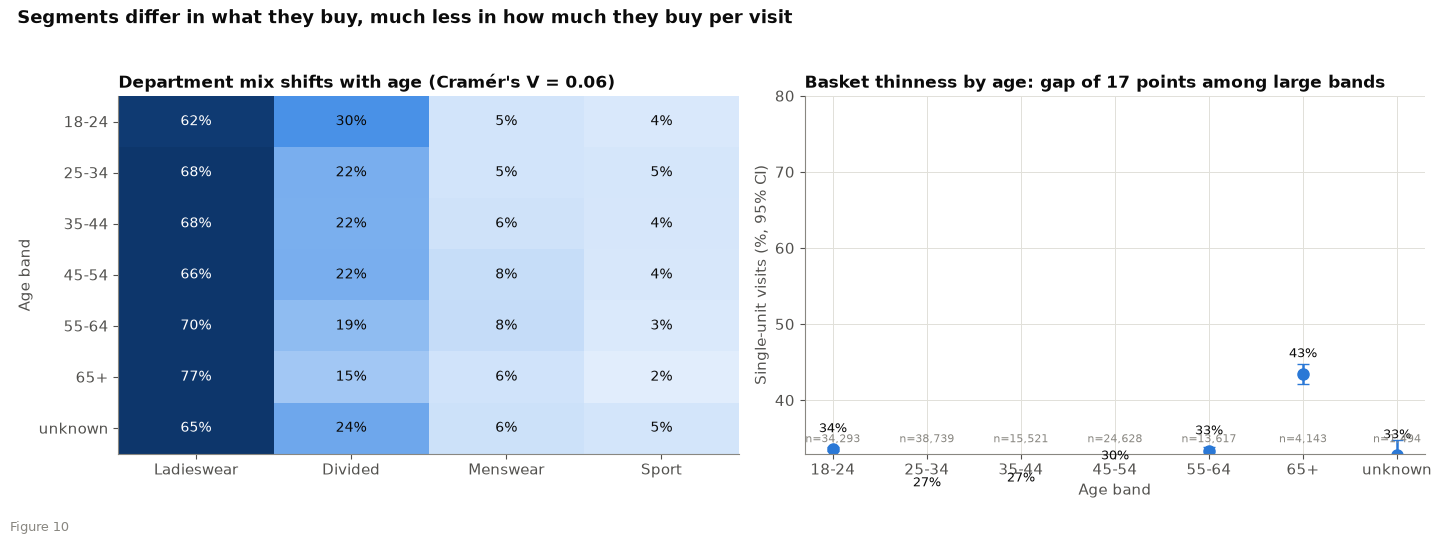

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 4.9), gridspec_kw={"width_ratios": [1.0, 1.0]})
im = ax[0].imshow(mix.values * 100, cmap=SEQ, aspect="auto", vmin=0, vmax=65)
ax[0].grid(False); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(mix.columns); ax[0].set_yticks(range(len(mix))); ax[0].set_yticklabels(mix.index)
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]): ax[0].text(j, i, f"{mix.values[i, j]*100:.0f}%", ha="center", va="center", fontsize=10, color="white" if mix.values[i, j]*100 > 36 else C["ink"])
ax[0].set_ylabel("Age band"); ax[0].set_title(f"Department mix shifts with age (Cramér's V = {cramer:.2f})")
s_ = seg.loc[BAND_ORDER[1:]]
xs_ = np.arange(len(s_))
ax[1].errorbar(xs_, s_["single share"] * 100, yerr=[(s_["single share"] - s_["s lo"]) * 100, (s_["s hi"] - s_["single share"]) * 100], fmt="o", color=C["blue"], ms=8, capsize=4, lw=1.8)
for i, (v_, n_) in enumerate(zip(s_["single share"], s_["customers"])): ax[1].text(i, v_ * 100 + 2.2, f"{v_:.0%}", ha="center", fontsize=9.5); ax[1].text(i, 34.5, f"n={n_:,}", ha="center", fontsize=8, color=C["muted"])
ax[1].set_xticks(xs_); ax[1].set_xticklabels(s_.index); ax[1].set_ylim(33, 80); ax[1].set_ylabel("Single-unit visits (%, 95% CI)"); ax[1].set_xlabel("Age band")
ax[1].set_title(f"Basket thinness by age: gap of {gap_single*100:.0f} points among large bands")
fig.suptitle("Segments differ in what they buy, much less in how much they buy per visit", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "fig10_segments_age")

### 7.2 H7: Colour mix and season

top 3 colours (Black, White, Blue): 61.6% of units with a known colour; colours covering 80%: 7 of 20


light/bright share of units: summer (Jun-Aug) 41.7% vs winter (Dec-Feb) 30.4%; gap 11.4 points


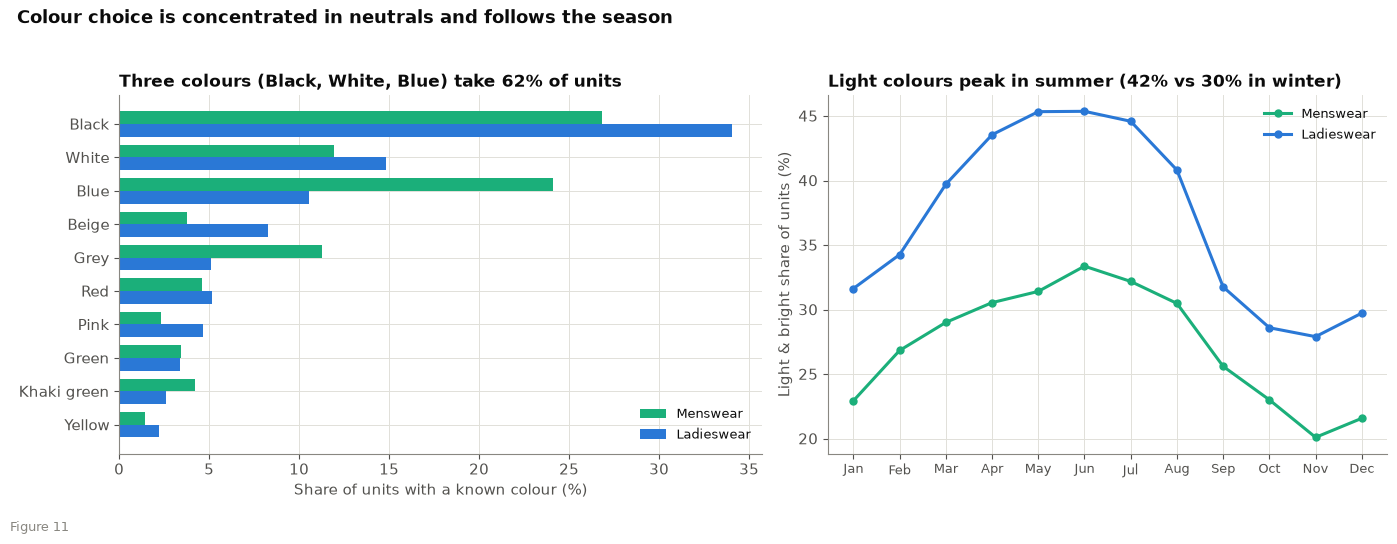

In [26]:
known = lines[~lines.perceived_colour_master_name.isin(["Unknown", "undefined"])]
col_all = known.groupby("perceived_colour_master_name").qty.sum().sort_values(ascending=False); col_sh = col_all / col_all.sum()
top3 = float(col_sh.iloc[:3].sum()); top3_names = list(col_sh.index[:3])
print(f"top 3 colours ({', '.join(top3_names)}): {top3:.1%} of units with a known colour; colours covering 80%: {int((col_sh.cumsum() < 0.8).sum() + 1)} of {len(col_sh)}")
by_dept = known[known.index_group_name.isin(["Menswear", "Ladieswear"])].groupby(["index_group_name", "perceived_colour_master_name"]).qty.sum().unstack(0)
by_dept = by_dept / by_dept.sum()
top_c = col_sh.index[:10]

LIGHT = ["Light", "Dusty Light", "Bright"]; DARK = ["Dark", "Medium Dark"]
vv = lines[lines.perceived_colour_value_name.isin(LIGHT + DARK + ["Medium Dusty"])].copy()
vv["is_light"] = vv.perceived_colour_value_name.isin(LIGHT); vv["month"] = vv.t_dat.dt.month
seas = vv.groupby("month").apply(lambda g: (g.qty * g.is_light).sum() / g.qty.sum())
seas_d = vv[vv.index_group_name.isin(["Menswear", "Ladieswear"])].groupby(["index_group_name", "month"]).apply(lambda g: (g.qty * g.is_light).sum() / g.qty.sum()).unstack(0)
summer, winter = seas.loc[[6, 7, 8]].mean(), seas.loc[[12, 1, 2]].mean()
print(f"light/bright share of units: summer (Jun-Aug) {summer:.1%} vs winter (Dec-Feb) {winter:.1%}; gap {abs(summer-winter)*100:.1f} points")
KEY.update(top3_colour=top3, top3_names=top3_names, light_summer=float(summer), light_winter=float(winter),
           black_share_men=float(by_dept.loc["Black", "Menswear"]), black_share_ladies=float(by_dept.loc["Black", "Ladieswear"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1.15, 1]})
y_ = np.arange(len(top_c))[::-1]; h = 0.38
ax[0].barh(y_ + h/2, by_dept.loc[top_c, "Menswear"] * 100, h, color=C["aqua"], label="Menswear")
ax[0].barh(y_ - h/2, by_dept.loc[top_c, "Ladieswear"] * 100, h, color=C["blue"], label="Ladieswear")
ax[0].set_yticks(y_); ax[0].set_yticklabels(top_c); ax[0].set_xlabel("Share of units with a known colour (%)"); ax[0].legend(fontsize=9.5)
ax[0].set_title(f"Three colours ({', '.join(top3_names)}) take {top3:.0%} of units")
mnames = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax[1].plot(range(1, 13), seas_d["Menswear"] * 100, color=C["aqua"], lw=2.2, marker="o", ms=5, label="Menswear")
ax[1].plot(range(1, 13), seas_d["Ladieswear"] * 100, color=C["blue"], lw=2.2, marker="o", ms=5, label="Ladieswear")
ax[1].set_xticks(range(1, 13)); ax[1].set_xticklabels(mnames, fontsize=9); ax[1].set_ylabel("Light & bright share of units (%)"); ax[1].legend(fontsize=9.5)
ax[1].set_title(f"Light colours peak in summer ({summer:.0%} vs {winter:.0%} in winter)")
fig.suptitle("Colour choice is concentrated in neutrals and follows the season", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "fig11_colour")

### 7.3 A behavioural proxy for the charter's target group

The charter's target group buys one safe item and leaves, and relies on suggestions. Transactions cannot show confidence or effort, so we define a **proxy** with a rule fixed here: customers with at least 4 visits of which at least 60% are single-unit visits. This is a hypothesis about behaviour, not a measurement of the group; the M3 survey must confirm it.

repeat customers (>=4 visits): 61,014 = 46.1% of customers; proxy segment is 9.7% of them and 3.5% of their units


,proxy segment,other repeat customers
median visits,7.000,9.000
median age,32.000,30.000
median distinct product types,7.000,12.000
share with unknown age,0.010,0.010


,proxy segment,other repeat customers
index_group_name,,
Divided,0.216,0.234
Ladieswear,0.687,0.668
Menswear,0.065,0.058
Sport,0.032,0.040


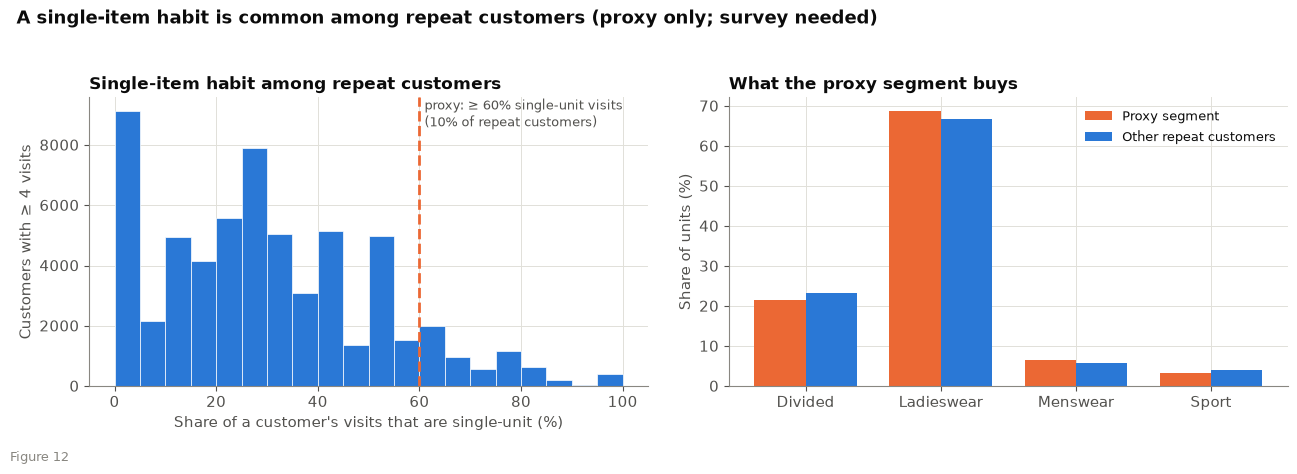

In [27]:
rep_ = cust[cust.n_visits >= 4].copy()
rep_["proxy"] = rep_.single_share >= 0.6
share_cust = rep_.proxy.mean(); share_units = rep_.loc[rep_.proxy, "units"].sum() / rep_.units.sum()
dept_units = lines.groupby(["cust", "index_group_name"]).qty.sum().unstack().fillna(0)
dm = dept_units.reindex(rep_.index)
mixp = pd.DataFrame({"proxy segment": dm[rep_.proxy].sum() / dm[rep_.proxy].sum().sum(), "other repeat customers": dm[~rep_.proxy].sum() / dm[~rep_.proxy].sum().sum()})
prof = pd.DataFrame({"proxy segment": [rep_[rep_.proxy].n_visits.median(), rep_[rep_.proxy].age_clean.median(), rep_[rep_.proxy].n_types.median(), (rep_[rep_.proxy].age_band == "unknown").mean()],
                     "other repeat customers": [rep_[~rep_.proxy].n_visits.median(), rep_[~rep_.proxy].age_clean.median(), rep_[~rep_.proxy].n_types.median(), (rep_[~rep_.proxy].age_band == "unknown").mean()]},
                    index=["median visits", "median age", "median distinct product types", "share with unknown age"])
print(f"repeat customers (>=4 visits): {len(rep_):,} = {len(rep_)/len(cust):.1%} of customers; proxy segment is {share_cust:.1%} of them and {share_units:.1%} of their units")
display(prof.round(2)); display(mixp.round(3))
KEY.update(proxy_share_cust=float(share_cust), proxy_share_units=float(share_units), n_repeat=int(len(rep_)), proxy_types=float(prof.loc["median distinct product types", "proxy segment"]),
           other_types=float(prof.loc["median distinct product types", "other repeat customers"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(rep_.single_share * 100, bins=np.arange(0, 105, 5), color=C["blue"], edgecolor="white", lw=0.5)
ax[0].axvline(60, color=C["orange"], lw=2, ls="--"); ax[0].text(61, ax[0].get_ylim()[1] * 0.9, f"proxy: ≥ 60% single-unit visits\n({share_cust:.0%} of repeat customers)", fontsize=9.5, color=C["ink2"])
ax[0].set_xlabel("Share of a customer's visits that are single-unit (%)"); ax[0].set_ylabel("Customers with ≥ 4 visits"); ax[0].set_title("Single-item habit among repeat customers")
x = np.arange(4); w = 0.38
ax[1].bar(x - w/2, mixp["proxy segment"] * 100, w, color=C["orange"], label="Proxy segment"); ax[1].bar(x + w/2, mixp["other repeat customers"] * 100, w, color=C["blue"], label="Other repeat customers")
ax[1].set_xticks(x); ax[1].set_xticklabels(mixp.index); ax[1].set_ylabel("Share of units (%)"); ax[1].legend(fontsize=9.5); ax[1].set_title("What the proxy segment buys")
fig.suptitle("A single-item habit is common among repeat customers (proxy only; survey needed)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout(); save(fig, "fig12_target_proxy")

## 8. Hypothesis verdicts

Each rule from section 1 is applied to the numbers computed above, using the thresholds fixed before the data was loaded.

In [28]:
H = KEY["hist"]
checks = [
    ("H1", "Thin baskets, outfit rarely complete",
     f"single-unit visits {KEY['p_single']:.1%} (≥ {THR['H1_single_min']:.0%}); top+bottom visits {KEY['p_pair']:.1%} (≤ {THR['H1_pair_max']:.0%})",
     KEY["p_single"] >= THR["H1_single_min"] and KEY["p_pair"] <= THR["H1_pair_max"]),
    ("H2", "History predicts next purchase",
     f"product type {H['Product type']['ratio']:.2f}×, colour {H['Colour (master)']['ratio']:.2f}× the random baseline (≥ {THR['H2_ratio_min']}×)",
     H["Product type"]["ratio"] >= THR["H2_ratio_min"] and H["Colour (master)"]["ratio"] >= THR["H2_ratio_min"]),
    ("H3", "Top-bottom pairs are complementary",
     f"median adjusted lift of top×bottom pairs {KEY['lift_tb_median']:.2f} (≥ {THR['H3_lift_min']}); top×top {KEY['lift_tt_median']:.2f}",
     KEY["lift_tb_median"] >= THR["H3_lift_min"]),
    ("H4", "Long tail and fast churn",
     f"top 1% of articles hold {KEY['top1_art']:.1%} (< {THR['H4_top1pct_max']:.0%}); top-100 overlap at 1 week {KEY['jac1']:.2f} (< {THR['H4_jaccard_max']}; noise ceiling {KEY['jac_ceiling']:.2f})",
     KEY["top1_art"] < THR["H4_top1pct_max"] and KEY["jac1"] < THR["H4_jaccard_max"]),
    ("H5", "Segments differ",
     f"Cramér's V {KEY['cramer']:.2f} (≥ {THR['H5_cramer_min']}); single-unit share gap {KEY['single_gap']*100:.1f} pts (≥ {THR['H5_gap_min']*100:.0f})",
     KEY["cramer"] >= THR["H5_cramer_min"] and KEY["single_gap"] >= THR["H5_gap_min"]),
    ("H6", "Heavy buyers dominate",
     f"top 10% of customers buy {KEY['top10_units']:.1%} of units (≥ {THR['H6_top10_min']:.0%}); Gini {KEY['gini']:.2f}",
     KEY["top10_units"] >= THR["H6_top10_min"]),
    ("H7", "Colour concentrated and seasonal",
     f"top 3 colours {KEY['top3_colour']:.1%} (≥ {THR['H7_top3_min']:.0%}); light share summer {KEY['light_summer']:.1%} vs winter {KEY['light_winter']:.1%} ({abs(KEY['light_summer']-KEY['light_winter'])*100:.1f} pts, ≥ {THR['H7_season_min']*100:.0f})",
     KEY["top3_colour"] >= THR["H7_top3_min"] and abs(KEY["light_summer"] - KEY["light_winter"]) >= THR["H7_season_min"]),
]
verd = pd.DataFrame(checks, columns=["ID", "hypothesis", "evidence vs pre-set rule", "supported"])
verd["verdict"] = np.where(verd.supported, "Supported", "Not supported")
verd = verd.drop(columns="supported").set_index("ID")
KEY["verdicts"] = verd.verdict.to_dict()
with pd.option_context("display.max_colwidth", None):
    display(verd)

,hypothesis,evidence vs pre-set rule,verdict
ID,,,
H1,"Thin baskets, outfit rarely complete",single-unit visits 30.1% (≥ 50%); top+bottom visits 22.2% (≤ 15%),Not supported
H2,History predicts next purchase,"product type 1.26×, colour 1.07× the random baseline (≥ 1.5×)",Not supported
H3,Top-bottom pairs are complementary,median adjusted lift of top×bottom pairs 1.35 (≥ 1.2); top×top 1.36,Supported
H4,Long tail and fast churn,top 1% of articles hold 14.4% (< 25%); top-100 overlap at 1 week 0.29 (< 0.5; noise ceiling 0.37),Supported
H5,Segments differ,Cramér's V 0.06 (≥ 0.15); single-unit share gap 17.0 pts (≥ 5),Not supported
H6,Heavy buyers dominate,top 10% of customers buy 48.0% of units (≥ 40%); Gini 0.64,Supported
H7,Colour concentrated and seasonal,"top 3 colours 61.6% (≥ 50%); light share summer 41.7% vs winter 30.4% (11.4 pts, ≥ 5)",Supported


**Reading the verdicts.** Four hypotheses are supported and three are not, under rules fixed before the data was loaded. The three that fail are the most useful for the project, because each corrects an assumption in the charter:

* **H1 fails.** Baskets are not thin on average; the opportunity is an *incomplete outfit* (a top without a bottom), not a one-item visit.
* **H2 fails as written.** Coarse history (product type, colour, department) beats chance only slightly. The strong signal is exact-article repeat buying (about 19× chance), which the rule did not test directly.
* **H5 fails on the department-mix part** but the basket-thinness gap across age bands is large (17 points). The rule required both, so the verdict stays "Not supported", and the gap is carried into the insight log.

Two supported verdicts need a caveat. **H3:** top×top pairs show the same lift as top×bottom pairs, so co-purchase cannot by itself separate complements from alternatives. **H4:** the lag-1 overlap threshold (0.50) is above the sampling-noise ceiling (about 0.37), so that half of the rule was easy to pass; the 4-week and 13-week overlaps and the next-week coverage are the stronger evidence.

## 9. Insight log

**Confidence levels.** *High*: large sample, narrow interval, same direction on raw and cleaned data. *Medium*: solid in the H&M data but rests on an unverified label, a noisy measure, or an assumption that Westside data must confirm. *Low*: a behavioural proxy or a pattern we cannot validate with these data.

In [29]:
H = KEY["hist"]
tbp = pairs[(pairs.roles.isin(["Top x Bottom", "Bottom x Top"])) & (pairs["visits together"] >= 200)].sort_values("adjusted lift", ascending=False).iloc[0]
ch1, ch2 = KEY["seg_ch"]["1"], KEY["seg_ch"]["2"]
sa = KEY["seg_age"]
rows = [
 ("I1", "Baskets are not thin on average; outfits are incomplete. Among visits that include a garment, fewer than half (45%) are complete (top + bottom, or full-body).",
  f"Fig 5. Single-unit visits {KEY['p_single']:.1%} (95% CI {KEY['p_single_lo']:.1%}-{KEY['p_single_hi']:.1%}); mean {KEY['mean_units_visit']:.1f} units per visit; garment visits: complete {KEY['complete']:.0%}, top only {KEY['top_only']:.0%}, bottom only {KEY['bottom_only']:.0%}.",
  "The charter's 'buys one item and leaves' premise does not hold for the average shopper. Target the mirror at the top-only and bottom-only moments and set the items-per-bill baseline at about 3.5 units, not 1. Revise the uplift assumptions in the M6 simulation.",
  "High (H&M data); Medium for transfer to Westside", "H1, BQ1"),
 ("I2", "Thin baskets sit in one sales channel.",
  f"Section 7.1. Single-unit share {ch1:.0%} in channel 1 vs {ch2:.0%} in channel 2; units per visit about 2.5 vs 4.1.",
  "If channel 1 is the physical store (the file does not say), the headroom is where the mirror will stand. Confirm the channel meaning before the simulation uses it; until then do not claim an in-store effect.",
  "Medium (channel label unverified)", "H1, BQ1"),
 ("I3", "A customer's own history is a strong predictor only at the level of the exact article. Product type and colour history add little over what is popular that week.",
  f"Fig 6. Exact-article repeat {H['Exact article (repeat purchase)']['real']:.1%} vs {H['Exact article (repeat purchase)']['base']:.1%} random ({H['Exact article (repeat purchase)']['ratio']:.0f}x); product type {H['Product type']['ratio']:.2f}x; colour {H['Colour (master)']['ratio']:.2f}x; department {H['Department']['ratio']:.2f}x. {KEY['items_eval']:,} items evaluated.",
  "Expect the recommender's edge over best-sellers to come from re-buy and from item-to-item cross-selling, not from learning a shopper's 'taste' in category or colour. Build article-level repeat and recency features first; treat taste embeddings as a second step.",
  "Medium (ratio depends on history length; measured on H&M only)", "H2, BQ2"),
 ("I4", "Purchases show which types are bought together, but not which are complements. Top x bottom pairs and top x top pairs have the same lift.",
  f"Fig 7. Median adjusted lift: top x bottom {KEY['lift_tb_median']:.2f} ({KEY['lift_tb_share12']:.0%} of pairs at 1.2 or more), top x top {KEY['lift_tt_median']:.2f}. Strongest top x bottom pair with 200+ visits: {tbp['type A']} + {tbp['type B']} (lift {tbp['adjusted lift']:.2f}).",
  "Use co-purchase only as a candidate generator for the outfit matcher. Compatibility must be learned from Polyvore outfit labels and judged on fill-in-the-blank accuracy, as the charter plans; do not evaluate the matcher on H&M co-purchase.",
  "Medium", "H3, BQ3"),
 ("I5", "Demand turns over fast. A best-seller list is stale within weeks, and new articles carry a large share of sales.",
  f"Fig 9. Last week's top 12 / 100 / 500 cover {KEY['cov12']:.1%} / {KEY['cov100']:.1%} / {KEY['cov500']:.1%} of next week's units. Top-100 overlap {KEY['jac1']:.2f} at 1 week (sampling ceiling {KEY['jac_ceiling']:.2f}), {KEY['jac4']:.2f} at 4 weeks, {KEY['jac52']:.2f} at 52. {KEY['novelty']:.0%} of weekly units come from articles first sold 8 weeks earlier or less.",
  "Recompute the best-seller baseline weekly on a short window and validate by date, never by random rows. Forecasts and suggestions need an attribute-based fallback for new articles. The MAP@12 target of three times the baseline is demanding because the baseline itself is weak at the article level.",
  "High (direction); Medium (levels, 10% sample is noisy)", "H4, BQ4"),
 ("I6", "A minority of heavy buyers dominates the data and a large group has almost no history.",
  f"Fig 3. Top 10% of customers buy {KEY['top10_units']:.0%} of units (Gini {KEY['gini']:.2f}); {KEY['one_visit_cust']:.0%} of customers have one visit; customers with unknown age or club status have a median of 1 visit vs 3 for others.",
  "Split train/test by customer, report metrics by activity tier, and weight or stratify so heavy buyers do not set the model. A third of members would meet the mirror with no history, so a popularity or content-based fallback is required, not optional.",
  "High", "H6, BQ2, BQ5"),
 ("I7", "Segments differ more in basket thinness than in what they buy. Older shoppers buy the fewest items per visit.",
  f"Fig 10. Single-unit share: 65+ {sa['65+']['single']:.0%} (CI {sa['65+']['lo']:.0%}-{sa['65+']['hi']:.0%}), 18-24 {sa['18-24']['single']:.0%}, 25-34 {sa['25-34']['single']:.0%}; gap {KEY['single_gap']*100:.0f} points. Department mix vs age: Cramer's V {KEY['cramer']:.2f} (weak).",
  "Evaluate quality by age band at one fixed setting (M5 fairness plan). A pooled model will be tuned to 25-34 baskets; older shoppers need single-item completion. Department is only a weak age signal, so age cannot be inferred from what is in the basket.",
  "High", "H5, BQ5"),
 ("I8", "Colour choice is concentrated in three neutrals and follows the season.",
  f"Fig 11. {', '.join(KEY['top3_names'])} = {KEY['top3_colour']:.0%} of units with a known colour. Light/bright share {KEY['light_summer']:.0%} in Jun-Aug vs {KEY['light_winter']:.0%} in Dec-Feb.",
  "For about two thirds of purchases colour matching is a choice among neutrals, so the incremental value of skin-tone-based colour advice is likely small and must be shown in the M5 colour-choice comparison. Add month and season to every model.",
  "Medium (colour attribute is the catalogue's, not the shopper's)", "H7, BQ3, BQ4"),
 ("I9", "The sample is not the bias; the proxy and the period are. The 10% sample matches the full file on every check, but 2020 is a structural break.",
  f"Figs 1-3. {KEY['rep_raw_pass']} of {KEY['rep_checks']} representativeness checks pass on raw data and the cleaned frame (max |SMD| {KEY['max_abs_smd_cust_clean']:.2f}). Mar-Aug 2020 units were {KEY['vol_2020_vs_2019']*100:+.0f}% vs 2019; channel-2 share {KEY['ch2_pre']:.0%} to {KEY['ch2_post']:.0%}. Baby/Children is {KEY['baby_units_share']:.1%} of raw units and was removed.",
  "Do not tune on the 2020 weeks alone; test models before and after March 2020. State in D4/D5 that results are patterns from European H&M data and must be re-validated on Westside data, as the charter says.",
  "High (sample); Medium (cause of the 2020 break)", "Bias checks"),
 ("I10", "The 'single-item habit' group the charter targets is visible but small, and transactions cannot show confidence or effort.",
  f"Fig 12. Proxy (4+ visits, 60%+ single-unit): {KEY['proxy_share_cust']:.1%} of {KEY['n_repeat']:,} repeat customers and {KEY['proxy_share_units']:.1%} of their units; median {KEY['proxy_types']:.0f} distinct product types vs {KEY['other_types']:.0f}.",
  "Do not size the business case on this proxy. The shopper survey planned for M3 must establish whether low-effort, low-confidence dressers exist at Westside and how large the group is.",
  "Low", "BQ5"),
]
insight_log = pd.DataFrame(rows, columns=["ID", "Insight", "Evidence (figure / number)", "So-what for the decision", "Confidence", "Hypothesis / question"]).set_index("ID")
insight_log.to_csv(OUT / "insight_log.csv", encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", None):
    display(insight_log.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap", "vertical-align": "top"}).set_table_styles(
        [{"selector": "th", "props": [("text-align", "left")]}]))

,Insight,Evidence (figure / number),So-what for the decision,Confidence,Hypothesis / question
ID,,,,,
I1,"Baskets are not thin on average; outfits are incomplete. Among visits that include a garment, fewer than half (45%) are complete (top + bottom, or full-body).","Fig 5. Single-unit visits 30.1% (95% CI 30.0%-30.3%); mean 3.5 units per visit; garment visits: complete 45%, top only 38%, bottom only 17%.","The charter's 'buys one item and leaves' premise does not hold for the average shopper. Target the mirror at the top-only and bottom-only moments and set the items-per-bill baseline at about 3.5 units, not 1. Revise the uplift assumptions in the M6 simulation.",High (H&M data); Medium for transfer to Westside,"H1, BQ1"
I2,Thin baskets sit in one sales channel.,Section 7.1. Single-unit share 38% in channel 1 vs 25% in channel 2; units per visit about 2.5 vs 4.1.,"If channel 1 is the physical store (the file does not say), the headroom is where the mirror will stand. Confirm the channel meaning before the simulation uses it; until then do not claim an in-store effect.",Medium (channel label unverified),"H1, BQ1"
I3,A customer's own history is a strong predictor only at the level of the exact article. Product type and colour history add little over what is popular that week.,"Fig 6. Exact-article repeat 5.4% vs 0.3% random (19x); product type 1.26x; colour 1.07x; department 1.05x. 2,360,065 items evaluated.","Expect the recommender's edge over best-sellers to come from re-buy and from item-to-item cross-selling, not from learning a shopper's 'taste' in category or colour. Build article-level repeat and recency features first; treat taste embeddings as a second step.",Medium (ratio depends on history length; measured on H&M only),"H2, BQ2"
I4,"Purchases show which types are bought together, but not which are complements. Top x bottom pairs and top x top pairs have the same lift.","Fig 7. Median adjusted lift: top x bottom 1.35 (68% of pairs at 1.2 or more), top x top 1.36. Strongest top x bottom pair with 200+ visits: Vest top + Shorts (lift 1.82).","Use co-purchase only as a candidate generator for the outfit matcher. Compatibility must be learned from Polyvore outfit labels and judged on fill-in-the-blank accuracy, as the charter plans; do not evaluate the matcher on H&M co-purchase.",Medium,"H3, BQ3"
I5,"Demand turns over fast. A best-seller list is stale within weeks, and new articles carry a large share of sales.","Fig 9. Last week's top 12 / 100 / 500 cover 1.6% / 8.4% / 24.6% of next week's units. Top-100 overlap 0.29 at 1 week (sampling ceiling 0.37), 0.13 at 4 weeks, 0.05 at 52. 39% of weekly units come from articles first sold 8 weeks earlier or less.","Recompute the best-seller baseline weekly on a short window and validate by date, never by random rows. Forecasts and suggestions need an attribute-based fallback for new articles. The MAP@12 target of three times the baseline is demanding because the baseline itself is weak at the article level.","High (direction); Medium (levels, 10% sample is noisy)","H4, BQ4"
I6,A minority of heavy buyers dominates the data and a large group has almost no history.,Fig 3. Top 10% of customers buy 48% of units (Gini 0.64); 32% of customers have one visit; customers with unknown age or club status have a median of 1 visit vs 3 for others.,"Split train/test by customer, report metrics by activity tier, and weight or stratify so heavy buyers do not set the model. A third of members would meet the mirror with no history, so a popularity or content-based fallback is required, not optional.",High,"H6, BQ2, BQ5"
I7,Segments differ more in basket thinness than in what they buy. Older shoppers buy the fewest items per visit.,"Fig 10. Single-unit share: 65+ 43% (CI 42%-45%), 18-24 34%, 25-34 27%; gap 17 points. Department mix vs age: Cramer's V 0.06 (weak).","Evaluate quality by age band at one fixed setting (M5 fairness plan). A pooled model will be tuned to 25-34 baskets; older shoppers need 

## 10. Summary: what matters most and how it shapes modelling

**The five insights that matter most**

1. **The gap is the incomplete outfit, not the one-item basket (I1, I2).** Fewer than half (45%) of garment visits are complete; 30% of visits are single-unit and the thin baskets sit in one channel. The mirror's job is to complete the outfit, and the items-per-bill baseline is about 3.5, not 1.
2. **History is useful for re-buying, not for taste (I3).** Exact-article repeat is about 19 times chance; product type and colour history barely beat a same-week random draw. M4 should start from repeat and recency features, then item-to-item co-purchase, before any taste embedding.
3. **Demand churns within weeks (I5).** A one-week-old top-12 list covers about 1.6% of next week's units and 39% of weekly units come from articles launched in the last 8 weeks. The best-seller baseline must be rebuilt weekly, validation must be by date, and new articles need an attribute-based fallback.
4. **Heavy buyers dominate and many shoppers have no history (I6, I7).** Top 10% of customers buy 48% of units; a third have one visit; older shoppers have the thinnest baskets. Split by customer, report by activity tier and age band, and ship a cold-start fallback.
5. **Co-purchase does not identify complements (I4), and colour is mostly neutrals (I8).** Purchases are a candidate generator for the outfit matcher only; compatibility comes from Polyvore. Colour advice has limited headroom and must be tested against shopper-chosen colours in M5.

| M4/M5 component | What the EDA changes |
|---|---|
| Best-seller baseline | Weekly rebuild, short window; report coverage by K. Expect a low absolute score (top-12 covers about 1.6%). |
| Recommender | Features: exact-article repeat, recency, department, month. Fallback for one-visit and unknown-age members. Weight or stratify by customer activity. |
| Outfit matcher | Use co-purchase lift only to propose candidates; train and test on Polyvore (fill-in-the-blank), never on H&M co-purchase. |
| Demand forecast | Seasonal terms, article age, attribute pooling for new articles; evaluate by WAPE on later weeks, with a pre/post-March-2020 check. |
| Validation | Split by date and by customer; no random row split. Treat the 2020 weeks as a separate regime. |
| Fairness | Report quality by age band and activity tier at one fixed setting; department stands in for gender only as a labelled proxy. |
| Open items | Channel meaning; shopper survey for the target group; Westside data to re-validate every number here. |

In [30]:
# Persist headline numbers for the PDF summary and print run metadata
KEY["runtime_sec"] = round(time.time() - T0)
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
(OUT / "key_numbers.json").write_text(json.dumps(_clean(KEY), indent=2))
import platform, matplotlib, scipy
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | scipy {scipy.__version__}")
print(f"seed {SEED} | total runtime {KEY['runtime_sec']} s | figures: {len(list(FIG.glob('*.png')))} | outputs: {[p.name for p in OUT.iterdir()]}")

python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.11.1 | scipy 1.15.3
seed 42 | total runtime 59 s | figures: 12 | outputs: ['insight_log.csv', 'key_numbers.json']
